# T1-4c: Pure Strain — Spatial Refinement Study

## Verification Study — Tier 1 / Trivial Trajectories

**Goal:** refine the grid and check whether the interpolation and trajectory errors of the three lateral
interpolation schemes of **T1-4b** decay towards machine precision ($\sim 10^{-16}$).

| Scheme | Data location | Interpolator | Expected order in space |
|---|---|---|---|
| barycentric (node) | `n_node` | `UxLinearNodeConstantZC` (Parcels built-in) | 2 (exact for linear fields) |
| constant (face) | `n_face` | `UxConstantFaceConstantZC` (Parcels built-in) | 1 |
| least-squares (face) | `n_face` | `LinearFaceRecon` (custom, copied verbatim from T1-4b) | 2 (exact for linear fields) |

The study has two parts:

* **Part A — pure strain** $u=\varepsilon x,\ v=-\varepsilon y$ (the T1-4/T1-4b flow, as requested).
  The field is *linear*, so barycentric and least-squares interpolation are exact at *every* resolution;
  only the constant-face scheme has a spatial error, $O(\Delta x)$. We measure (i) the direct interpolation
  error at random interior points and (ii) the RK4 trajectory error at a fixed, very small $\Delta t$.
* **Part B — a smooth nonlinear (cellular) field** $u = U_0\sin kx\cos ky,\ v=-U_0\cos kx\sin ky$, for which every
  scheme has a genuine truncation error. Direct interpolation error only; this exposes the true spatial
  convergence orders and lets us extrapolate how fine a grid would be needed to reach $10^{-16}$.

**Known limitation (Parcels, not this notebook):** `UxGrid.search` (`parcels/_core/uxgrid.py`) casts the particle
coordinates to `float32` and returns the barycentric weights in `float32`. The barycentric *node* scheme therefore
has a relative error floor of order the float32 machine epsilon ($\approx 1.2\times10^{-7}$), independent of resolution.
It cannot reach $10^{-16}$ on any grid. This floor is shown below and marked as such; it is not a failure of the test.
The face schemes only use the *face index* from the search and evaluate in float64, so they are not affected.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import uxarray as ux
import xarray as xr

import parcels
from parcels._core.particle import get_default_particle

# Parcels' default Particle stores positions in float32; use float64 positions throughout.
Particle64 = get_default_particle(np.float64)
from uxarray.constants import INT_FILL_VALUE
from parcels.interpolators._base import ScalarInterpolator

EPS64 = np.finfo(np.float64).eps   # 2.2e-16
EPS32 = np.finfo(np.float32).eps   # 1.2e-7
NOTEBOOK_T0 = time.time()

## 1. Parameters

**Resolution sweep.** The grid is the T1-4b Delaunay triangulation of an $N_X\times N_X$ point lattice on
$[-5,5]^2$, with $N_X \in \{10, 20, 40, 80, 160, 320, 640\}$, i.e. node spacing $\Delta x = 10/(N_X-1)$ from
1.1 down to 0.016 (a factor 71). Prototyping showed that the run time per trajectory integration is dominated by the
per-step kernel overhead and is almost independent of the grid size (grid building takes ~6 s at $N_X=640$),
so the full range up to $N_X=640$ (~0.8 M triangles) is affordable.

**Time step for the trajectories (Part A).** We want the RK4 time-truncation error to be negligible compared with the
spatial error of every scheme, including the least-squares scheme whose spatial error is at round-off level.
From T1-4b (least-squares + RK4, near-origin particles, $T=2520$ s) the mean position error was
$1.8\times10^{-11}$ ($\Delta t=5$ s), $3.4\times10^{-14}$ (1 s), $4.9\times10^{-16}$ (0.5 s), and then *rose* again to
$\sim5\times10^{-15}$ for 0.25/0.125 s because round-off accumulates over more steps. RK4 global error scales as
$\Delta t^4 \cdot T$, so on the shorter $T=360$ s used here it is ~7x smaller still. We therefore use
**$\Delta t = 0.5$ s, $T=360$ s (720 RK4 steps)**: the time error is $\lesssim10^{-16}$, below float64 round-off,
and a run costs ~8-19 s. Section 4 re-checks this choice at $N_X=40$.

$T=360$ s with all 18 T1-4 particles (near / mid / far) keeps every particle inside the domain
($x(T) \le 3\,e^{0.36} = 4.3$).

In [2]:
# Domain (centered at origin = stagnation point)
HALF = 5.0
LON_MIN, LON_MAX = -HALF, HALF
LAT_MIN, LAT_MAX = -HALF, HALF

NX_VALUES = [10, 20, 40, 80, 160, 320, 640]
DX = {nx: (LON_MAX - LON_MIN) / (nx - 1) for nx in NX_VALUES}

# Part A: pure strain
EPSILON = 1e-3  # s^{-1}

# Part B: smooth nonlinear cellular flow, two wavelengths across the domain
U0 = 1e-3                    # degrees/s
K_WAVE = 2 * np.pi / 5.0     # wavelength 5 -> 2 wavelengths in [-5, 5]

# Trajectories (Part A)
T_TOTAL_S = 360.0
T_TOTAL = np.timedelta64(int(T_TOTAL_S), "s")
DT_S = 0.5
DT = np.timedelta64(int(DT_S * 1000), "ms")

# Single-snapshot velocity (steady field)
N_TIMESTEPS = 1
TIME = xr.date_range("2000-01-01", periods=N_TIMESTEPS, freq="2h")

# Particles: same 18 as T1-4 / T1-4b
p_coords_near = [(0.1, 0.1), (-0.1, 0.1), (0.1, -0.1), (-0.1, -0.1), (0.05, 0.2), (0.2, 0.05)]
p_coords_mid = [(1.0, 1.0), (-1.0, 1.0), (1.0, -1.0), (-1.0, -1.0), (0.5, 2.0), (2.0, 0.5)]
p_coords_far = [(3.0, 1.0), (-3.0, 1.0), (1.0, 3.0), (1.0, -3.0), (2.5, 2.5), (-2.5, -2.5)]
all_coords = p_coords_near + p_coords_mid + p_coords_far
p_lon0 = np.array([c[0] for c in all_coords], dtype=np.float64)
p_lat0 = np.array([c[1] for c in all_coords], dtype=np.float64)
N_PARTICLES = len(p_lon0)

# Random sample points for the direct interpolation error.
# Kept to [-3.5, 3.5]^2: away from the boundary and from the domain corners, where `regional_delaunay`
# drops a few corner triangles (n_face < 2 (NX-1)^2), which at NX=10 reach in to |x| ~ 3.9.
rng = np.random.default_rng(0)
N_SAMPLE = 20000
SAMPLE_HALF = 3.5
xs = rng.uniform(-SAMPLE_HALF, SAMPLE_HALF, N_SAMPLE)
ys = rng.uniform(-SAMPLE_HALF, SAMPLE_HALF, N_SAMPLE)
zs = np.full(N_SAMPLE, 0.5)

print("NX :", NX_VALUES)
print("dx :", [f"{DX[nx]:.4f}" for nx in NX_VALUES])
print(f"Part A: eps = {EPSILON:.0e} 1/s, T = {T_TOTAL_S:.0f} s, dt = {DT_S} s ({int(T_TOTAL_S / DT_S)} RK4 steps), "
      f"{N_PARTICLES} particles")
print(f"Part B: U0 = {U0:.0e}, k = {K_WAVE:.4f} (k*dx from {K_WAVE * DX[NX_VALUES[0]]:.2f} "
      f"to {K_WAVE * DX[NX_VALUES[-1]]:.4f})")

NX : [10, 20, 40, 80, 160, 320, 640]
dx : ['1.1111', '0.5263', '0.2564', '0.1266', '0.0629', '0.0313', '0.0156']
Part A: eps = 1e-03 1/s, T = 360 s, dt = 0.5 s (720 RK4 steps), 18 particles
Part B: U0 = 1e-03, k = 1.2566 (k*dx from 1.40 to 0.0197)


## 2. Grids and Datasets

Same construction as T1-4b, wrapped in a function of $N_X$. The dataset builder is generalised to take any
velocity function `uv_func(x, y) -> (u, v)`, evaluated at the face centres (`n_face` data) or at the nodes
(`n_node` data).

In [3]:
def build_grid(nx):
    lon, lat = np.meshgrid(
        np.linspace(LON_MIN, LON_MAX, nx, dtype=np.float64),
        np.linspace(LAT_MIN, LAT_MAX, nx, dtype=np.float64),
    )
    lon_flat, lat_flat = lon.ravel(), lat.ravel()
    mask = (
        np.isclose(lon_flat, LON_MIN) | np.isclose(lon_flat, LON_MAX)
        | np.isclose(lat_flat, LAT_MIN) | np.isclose(lat_flat, LAT_MAX)
    )
    uxgrid = ux.Grid.from_points(
        (lon_flat, lat_flat), method="regional_delaunay", boundary_points=np.flatnonzero(mask),
    )
    uxgrid.attrs["Conventions"] = "UGRID-1.0"
    return uxgrid


zf = np.array([0.0, 1.0], dtype=np.float64)
zc = np.array([0.5], dtype=np.float64)


def make_dataset(uxgrid, uv_func, location):
    # Velocity dataset with U, V on `location` ("face" or "node") and W = 0 on nodes.
    if location == "face":
        x, y, dim, n = uxgrid.face_lon.values, uxgrid.face_lat.values, "n_face", uxgrid.n_face
    else:
        x, y, dim, n = uxgrid.node_lon.values, uxgrid.node_lat.values, "n_node", uxgrid.n_node
    u_vals, v_vals = uv_func(x, y)
    U = np.broadcast_to(u_vals[None, None, :], (N_TIMESTEPS, zc.size, n)).copy()
    V = np.broadcast_to(v_vals[None, None, :], (N_TIMESTEPS, zc.size, n)).copy()
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)
    attrs = dict(location=location, mesh="delaunay", Conventions="UGRID-1.0", units="degrees/s")
    u = ux.UxDataArray(data=U, name="U", uxgrid=uxgrid, dims=["time", "zc", dim],
                       coords=dict(time=(["time"], TIME), zc=(["zc"], zc)), attrs=attrs)
    v = ux.UxDataArray(data=V, name="V", uxgrid=uxgrid, dims=["time", "zc", dim],
                       coords=dict(time=(["time"], TIME), zc=(["zc"], zc)), attrs=attrs)
    w = ux.UxDataArray(data=W, name="W", uxgrid=uxgrid, dims=["time", "zf", "n_node"],
                       coords=dict(time=(["time"], TIME), zf=(["zf"], zf)), attrs={**attrs, "location": "node"})
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


def strain_uv(x, y):
    return EPSILON * x, -EPSILON * y


def cellular_uv(x, y):
    return (U0 * np.sin(K_WAVE * x) * np.cos(K_WAVE * y),
            -U0 * np.cos(K_WAVE * x) * np.sin(K_WAVE * y))


GRIDS = {}
grid_rows = []
for nx in NX_VALUES:
    t0 = time.time()
    GRIDS[nx] = build_grid(nx)
    g = GRIDS[nx]
    grid_rows.append({"NX": nx, "dx": DX[nx], "n_node": g.n_node, "n_face": g.n_face,
                      "missing corner faces": 2 * (nx - 1) ** 2 - g.n_face,
                      "build time [s]": round(time.time() - t0, 2)})
df_grids = pd.DataFrame(grid_rows)
df_grids

,NX,dx,n_node,n_face,missing corner faces,build time [s]
0,10,1.111111,100,160,2,1.54
1,20,0.526316,400,719,3,0.00
2,40,0.256410,1600,3039,3,0.01
3,80,0.126582,6400,12479,3,0.04
4,160,0.062893,25600,50560,2,0.20
5,320,0.031348,102400,203519,3,1.13
6,640,0.015649,409600,816639,3,5.15


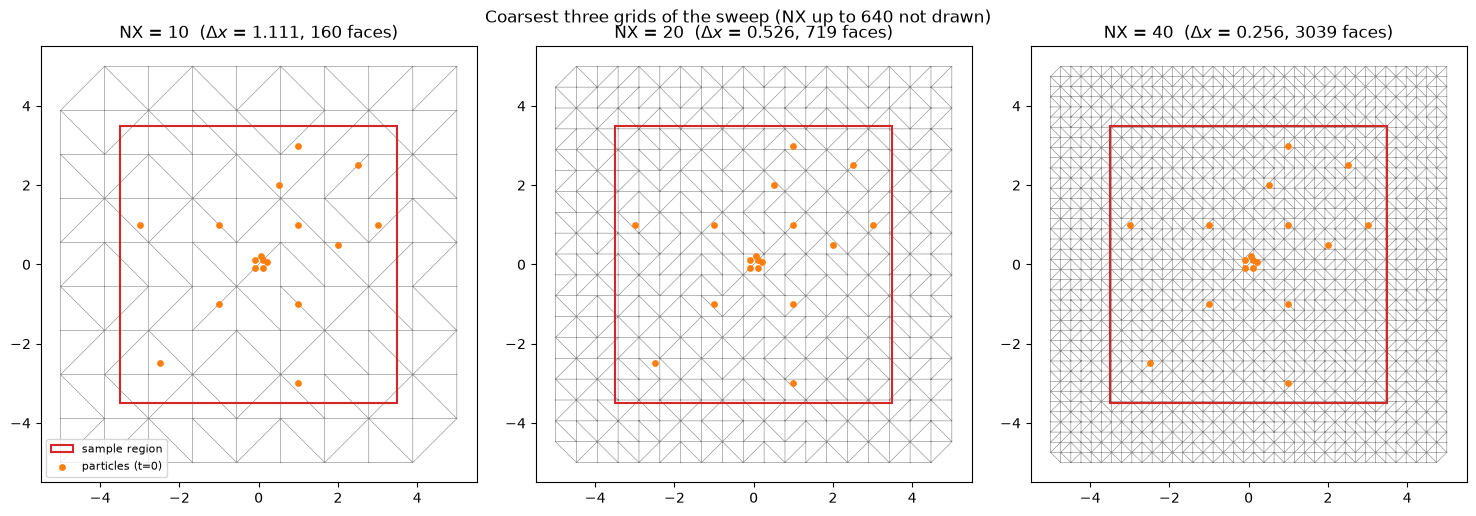

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, nx in zip(axes, [10, 20, 40]):
    g = GRIDS[nx]
    tri = mtri.Triangulation(g.node_lon.values, g.node_lat.values, triangles=g.face_node_connectivity.values)
    ax.triplot(tri, "k-", lw=0.4, alpha=0.5)
    ax.add_patch(plt.Rectangle((-SAMPLE_HALF, -SAMPLE_HALF), 2 * SAMPLE_HALF, 2 * SAMPLE_HALF,
                               fill=False, ec="C3", lw=1.5, label="sample region"))
    ax.scatter(p_lon0, p_lat0, c="C1", s=15, zorder=5, label="particles (t=0)")
    ax.set_title(f"NX = {nx}  ($\\Delta x$ = {DX[nx]:.3f}, {g.n_face} faces)")
    ax.set_aspect("equal")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Coarsest three grids of the sweep (NX up to 640 not drawn)")
plt.tight_layout()
plt.show()

## 3. Interpolators

`LinearFaceRecon` is copied verbatim from T1-4b (least-squares planar gradient fit over the face neighbours,
evaluated in float64 at the particle position).

In [5]:
DEG2M = 1852.0 * 60.0  # metres per degree (matches the Ux_Velocity unit conversion)


class LinearFaceRecon(ScalarInterpolator):
    """Linear least-squares reconstruction of face-registered data, constant in the vertical (zc)."""

    def __init__(self, uxgrid, spherical=False):
        self.spherical = spherical
        nbr = np.asarray(uxgrid.face_face_connectivity.values)          # (n_face, K)
        self.face_x = np.asarray(uxgrid.face_lon.values, dtype=np.float64)
        self.face_y = np.asarray(uxgrid.face_lat.values, dtype=np.float64)

        valid = nbr != INT_FILL_VALUE
        nbr_safe = np.where(valid, nbr, 0)
        dx, dy = self._offsets(self.face_x[:, None], self.face_y[:, None],
                               self.face_x[nbr_safe], self.face_y[nbr_safe])
        dx = np.where(valid, dx, 0.0)  # absent neighbour -> no contribution
        dy = np.where(valid, dy, 0.0)

        X2 = np.sum(dx * dx, axis=1)
        Y2 = np.sum(dy * dy, axis=1)
        XY = np.sum(dx * dy, axis=1)
        det = X2 * Y2 - XY * XY

        # < 2 independent neighbours -> singular system -> zero-gradient (piecewise-constant) fallback
        ok = det > 1e-12 * np.maximum(X2 * Y2, np.finfo(float).tiny)
        inv_det = np.where(ok, 1.0 / np.where(ok, det, 1.0), 0.0)

        self.gx = np.where(valid, (dx * Y2[:, None] - dy * XY[:, None]) * inv_det[:, None], 0.0)
        self.gy = np.where(valid, (dy * X2[:, None] - dx * XY[:, None]) * inv_det[:, None], 0.0)
        self.neighbors = nbr_safe
        self.mask = valid.astype(np.float64)
        self.n_fallback = int(np.sum(~ok))

    def _offsets(self, x_c, y_c, x, y):
        """Local planar offset of (x, y) from (x_c, y_c): metres on a sphere, grid units on a flat mesh."""
        if self.spherical:
            dlon = ((np.asarray(x) - x_c + 180.0) % 360.0) - 180.0
            return dlon * np.cos(np.deg2rad(y_c)) * DEG2M, (np.asarray(y) - y_c) * DEG2M
        return np.asarray(x) - x_c, np.asarray(y) - y_c

    def interp(self, particle_positions, grid_positions, field):
        ti, zi, fi = np.broadcast_arrays(
            grid_positions["T"]["index"], grid_positions["Z"]["index"], grid_positions["FACE"]["index"]
        )
        data = np.asarray(field.data.values)                            # (time, zc, n_face)

        u_c = data[ti, zi, fi]                                          # (M,)
        u_k = data[ti[:, None], zi[:, None], self.neighbors[fi]]        # (M, K)
        du = (u_k - u_c[:, None]) * self.mask[fi]
        a_x = np.sum(self.gx[fi] * du, axis=1)
        a_y = np.sum(self.gy[fi] * du, axis=1)

        dx, dy = self._offsets(self.face_x[fi], self.face_y[fi],
                               particle_positions["x"], particle_positions["y"])
        return u_c + a_x * dx + a_y * dy

In [6]:
SCHEMES = ["barycentric (node)", "constant (face)", "least-squares (face)"]
SCHEME_COLORS = {"barycentric (node)": "C0", "constant (face)": "C1", "least-squares (face)": "C2"}
MARKERS = {"barycentric (node)": "o", "constant (face)": "s", "least-squares (face)": "^"}


def make_fieldset(scheme, ds_node, ds_face):
    # Fresh FieldSet for one interpolation scheme.
    if scheme == "barycentric (node)":
        return parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")
    fieldset = parcels.FieldSet.from_ugrid_conventions(ds_face, mesh="flat")
    if scheme == "least-squares (face)":
        recon = LinearFaceRecon(fieldset.fields["U"].grid.uxgrid, spherical=False)
        fieldset.fields["U"].interp_method = recon
        fieldset.fields["V"].interp_method = recon
    return fieldset


def direct_error(fieldset, uv_func):
    # Velocity-vector error at the random sample points; relative errors are normalised by max |u_exact|.
    # Guard: Field.eval silently returns 0 for points the grid search does not find.
    fi = fieldset.fields["U"].grid.search(zs, ys, xs)["FACE"]["index"]
    assert np.all(fi >= 0), f"{np.sum(fi < 0)} sample points not found by the grid search"
    u = fieldset.fields["U"].eval(0.0, zs, ys, xs)
    v = fieldset.fields["V"].eval(0.0, zs, ys, xs)
    ue, ve = uv_func(xs, ys)
    err = np.hypot(u - ue, v - ve)
    uref = np.max(np.hypot(ue, ve))
    return {"max_abs": err.max(), "rms_abs": np.sqrt(np.mean(err**2)),
            "max_rel": err.max() / uref, "rms_rel": np.sqrt(np.mean(err**2)) / uref}

## 4. Time-step check for the trajectory runs

Least-squares + RK4 at $N_X=40$ (spatially exact for this field), $T=360$ s, all 18 particles. The error should fall
as $\Delta t^4$ and then flatten at float64 round-off; $\Delta t=0.5$ s must lie on that plateau.

In [7]:
def analytical_position(lon0, lat0, epsilon, t_seconds):
    # Exact pure-strain position after t_seconds.
    return lon0 * np.exp(epsilon * t_seconds), lat0 * np.exp(-epsilon * t_seconds)


X_EXACT, Y_EXACT = analytical_position(p_lon0, p_lat0, EPSILON, T_TOTAL_S)


def run_rk4(fieldset, dt):
    pset = parcels.ParticleSet(fieldset, pclass=Particle64, x=p_lon0.copy(), y=p_lat0.copy())
    pset.execute(parcels.kernels.AdvectionRK4, runtime=T_TOTAL, dt=dt, verbose_progress=False)
    return np.hypot(pset.x - X_EXACT, pset.y - Y_EXACT)


ds_n40, ds_f40 = make_dataset(GRIDS[40], strain_uv, "node"), make_dataset(GRIDS[40], strain_uv, "face")
fs_lsq40 = make_fieldset("least-squares (face)", ds_n40, ds_f40)
dt_rows = []
for dt_s in [6.0, 3.0, 2.0, 1.0, 0.5, 0.25]:
    t0 = time.time()
    e = run_rk4(fs_lsq40, np.timedelta64(int(dt_s * 1000), "ms"))
    dt_rows.append({"dt [s]": dt_s, "steps": int(T_TOTAL_S / dt_s), "mean error": e.mean(),
                    "max error": e.max(), "wall [s]": round(time.time() - t0, 1)})
df_dt = pd.DataFrame(dt_rows)
print("float64 spacing at |x| = 0.14 / 1.4 / 4.3:",
      ", ".join(f"{np.spacing(a):.1e}" for a in (0.14, 1.4, 4.3)))
df_dt

float64 spacing at |x| = 0.14 / 1.4 / 4.3: 2.8e-17, 2.2e-16, 8.9e-16


,dt [s],steps,mean error,max error,wall [s]
0,6.00,60,7.254341e-12,1.685742e-11,0.8
1,3.00,120,4.535800e-13,1.053783e-12,1.2
2,2.00,180,8.969626e-14,2.061019e-13,1.8
3,1.00,360,5.872471e-15,1.454689e-14,3.6
4,0.50,720,1.443300e-15,3.109120e-15,7.2
5,0.25,1440,3.146264e-15,1.300052e-14,14.3


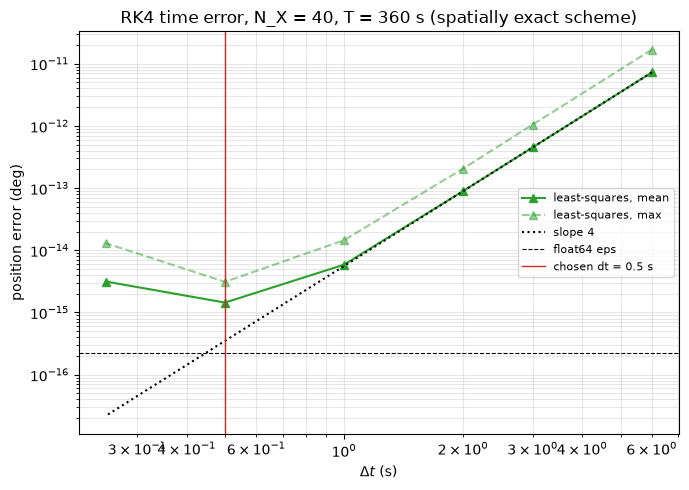

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(df_dt["dt [s]"], df_dt["mean error"], "^-", color="C2", label="least-squares, mean")
ax.loglog(df_dt["dt [s]"], df_dt["max error"], "^--", color="C2", alpha=0.5, label="least-squares, max")
d = df_dt["dt [s]"].values
ax.loglog(d, df_dt["mean error"].values[0] * (d / d[0]) ** 4, "k:", label="slope 4")
ax.axhline(EPS64, color="k", lw=0.8, ls="--", label="float64 eps")
ax.axvline(DT_S, color="C3", lw=1, label=f"chosen dt = {DT_S} s")
ax.set_xlabel(r"$\Delta t$ (s)"); ax.set_ylabel("position error (deg)")
ax.set_title("RK4 time error, N_X = 40, T = 360 s (spatially exact scheme)")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Part A — Pure strain: resolution sweep

For every $N_X$ and scheme: direct interpolation error at the 20 000 sample points, and the RK4 position error of the
18 particles after $T=360$ s with $\Delta t=0.5$ s (no particle file is written; only final positions are used).

In [9]:
rows_A = []
for nx in NX_VALUES:
    ds_node = make_dataset(GRIDS[nx], strain_uv, "node")
    ds_face = make_dataset(GRIDS[nx], strain_uv, "face")
    for scheme in SCHEMES:
        fs = make_fieldset(scheme, ds_node, ds_face)
        d = direct_error(fs, strain_uv)
        t0 = time.time()
        e = run_rk4(fs, DT)
        wall = time.time() - t0
        rows_A.append({"NX": nx, "dx": DX[nx], "scheme": scheme,
                       "interp_max_abs": d["max_abs"], "interp_rms_abs": d["rms_abs"],
                       "interp_max_rel": d["max_rel"], "interp_rms_rel": d["rms_rel"],
                       "traj_mean": e.mean(), "traj_max": e.max(),
                       "traj_max_ulp": np.max(e / np.spacing(np.hypot(X_EXACT, Y_EXACT))),
                       "wall_s": wall})
        print(f"NX={nx:4d} {scheme:22s} | interp max rel {d['max_rel']:.2e} rms rel {d['rms_rel']:.2e} | "
              f"traj mean {e.mean():.2e} max {e.max():.2e} | {wall:5.1f} s", flush=True)
df_A = pd.DataFrame(rows_A)

NX=  10 barycentric (node)     | interp max rel 6.35e-08 rms rel 1.72e-08 | traj mean 3.01e-10 max 7.32e-10 |  17.0 s


NX=  10 constant (face)        | interp max rel 1.67e-01 rms rel 7.27e-02 | traj mean 6.39e-02 max 1.77e-01 |  13.4 s


NX=  10 least-squares (face)   | interp max rel 1.81e-16 rms rel 4.93e-17 | traj mean 1.48e-15 max 3.11e-15 |   7.3 s


NX=  20 barycentric (node)     | interp max rel 5.73e-08 rms rel 1.71e-08 | traj mean 3.04e-10 max 6.88e-10 |  17.1 s


NX=  20 constant (face)        | interp max rel 7.91e-02 rms rel 3.60e-02 | traj mean 3.41e-02 max 7.49e-02 |  13.2 s


...

NX= 320 constant (face)        | interp max rel 4.73e-03 rms rel 2.11e-03 | traj mean 4.18e-04 max 1.16e-03 |  13.4 s


NX= 320 least-squares (face)   | interp max rel 1.76e-16 rms rel 4.53e-17 | traj mean 1.48e-15 max 3.11e-15 |   7.3 s


NX= 640 barycentric (node)     | interp max rel 5.92e-08 rms rel 1.70e-08 | traj mean 3.44e-10 max 8.10e-10 |  17.4 s


NX= 640 constant (face)        | interp max rel 2.36e-03 rms rel 1.06e-03 | traj mean 1.32e-04 max 8.51e-04 |  13.6 s


NX= 640 least-squares (face)   | interp max rel 1.81e-16 rms rel 4.62e-17 | traj mean 1.53e-15 max 3.11e-15 |   7.6 s


In [10]:
def fit_slope(dx, err):
    # Least-squares slope of log(err) vs log(dx), and prefactor C in err = C dx^p.
    p, logc = np.polyfit(np.log(dx), np.log(err), 1)
    return p, np.exp(logc)


ASYMPTOTIC_NX = 80   # fits for convergence orders use NX >= 80 (k*dx <= 0.16 in Part B)

pd.set_option("display.float_format", lambda v: f"{v:.3e}")
df_A.pivot(index="NX", columns="scheme",
           values=["interp_max_rel", "interp_rms_rel", "traj_mean", "traj_max", "wall_s"])

interp_max_rel                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              6.346e-08       1.668e-01            1.813e-16   
20              5.727e-08       7.912e-02            1.967e-16   
40              5.743e-08       3.827e-02            1.773e-16   
80              6.257e-08       1.907e-02            1.813e-16   
160             6.472e-08       9.486e-03            1.759e-16   
320             6.268e-08       4.728e-03            1.759e-16   
640             5.919e-08       2.359e-03            1.813e-16   

           interp_rms_rel                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              1.722e-08       7.268e-02            4.928e-17   
20              1.713e-08       3.604e-02            4.574e-17   
40              1.719e-08       1.744e-02            4.489e-17   
80              1.716e-08       8.606e-03            4.669e-17   
160             1.724e-08       4.291e-03            4.510e-17   
320             1.705e-08       2.112e-03            4.530e-17   
640             1.700e-08       1.058e-03            4.621e-17   

                traj_mean                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              3.014e-10       6.394e-02            1.483e-15   
20              3.042e-10       3.412e-02            1.463e-15   
40              3.016e-10       1.504e-02            1.443e-15   
80              2.976e-10       4.958e-03            1.482e-15   
160             3.027e-10       2.056e-03            1.482e-15   
320             2.953e-10       4.177e-04            1.482e-15   
640             3.443e-10       1.318e-04            1.531e-15   

                 traj_max                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              7.315e-10       1.769e-01            3.109e-15   
20              6.880e-10       7.492e-02            3.109e-15   
40              7.417e-10       6.057e-02            3.109e-15   
80              6.863e-10       1.453e-02            3.109e-15   
160             6.829e-10       5.988e-03            3.109e-15   
320             7.926e-10       1.156e-03            3.109e-15   
640             8.101e-10       8.513e-04            3.109e-15   

                   wall_s                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              1.698e+01       1.342e+01            7.297e+00  
20              1.705e+01       1.318e+01            7.171e+00  
40              1.686e+01       1.328e+01            7.399e+00  
80              1.692e+01       1.408e+01            7.258e+00  
160             1.737e+01       1.352e+01            7.410e+00  
320             1.687e+01       1.341e+01            7.290e+00  
640             1.738e+01       1.355e+01            7.582e+00

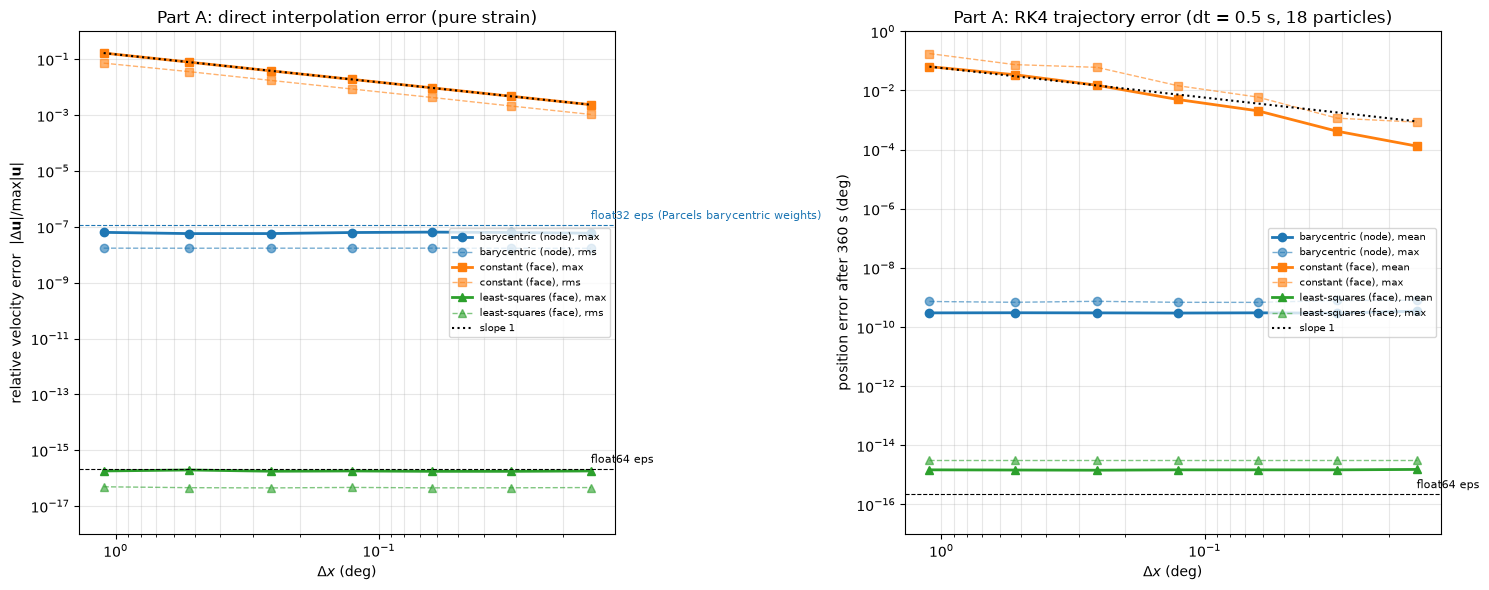

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
dxs = np.array([DX[nx] for nx in NX_VALUES])

ax = axes[0]
for scheme in SCHEMES:
    s = df_A[df_A["scheme"] == scheme]
    ax.loglog(s["dx"], s["interp_max_rel"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=2,
              label=f"{scheme}, max")
    ax.loglog(s["dx"], s["interp_rms_rel"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=1,
              ls="--", alpha=0.6, label=f"{scheme}, rms")
s = df_A[df_A["scheme"] == "constant (face)"]
ax.loglog(dxs, s["interp_max_rel"].values[0] * dxs / dxs[0], "k:", label="slope 1")
ax.axhline(EPS64, color="k", ls="--", lw=0.8)
ax.text(dxs[-1], EPS64 * 1.6, "float64 eps", fontsize=8)
ax.axhline(EPS32, color="C0", ls="--", lw=0.8)
ax.text(dxs[-1], EPS32 * 1.6, "float32 eps (Parcels barycentric weights)", fontsize=8, color="C0")
ax.set_xlabel(r"$\Delta x$ (deg)"); ax.set_ylabel(r"relative velocity error  $|\Delta\mathbf{u}|/\max|\mathbf{u}|$")
ax.set_title("Part A: direct interpolation error (pure strain)")
ax.set_ylim(1e-18, 1)
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)

ax = axes[1]
for scheme in SCHEMES:
    s = df_A[df_A["scheme"] == scheme]
    ax.loglog(s["dx"], s["traj_mean"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=2,
              label=f"{scheme}, mean")
    ax.loglog(s["dx"], s["traj_max"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=1, ls="--",
              alpha=0.6, label=f"{scheme}, max")
s = df_A[df_A["scheme"] == "constant (face)"]
ax.loglog(dxs, s["traj_mean"].values[0] * dxs / dxs[0], "k:", label="slope 1")
ax.axhline(EPS64, color="k", ls="--", lw=0.8)
ax.text(dxs[-1], EPS64 * 1.6, "float64 eps", fontsize=8)
ax.set_xlabel(r"$\Delta x$ (deg)"); ax.set_ylabel("position error after 360 s (deg)")
ax.set_title(f"Part A: RK4 trajectory error (dt = {DT_S} s, {N_PARTICLES} particles)")
ax.set_ylim(1e-17, 1)
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
for a in axes:
    a.invert_xaxis()
plt.tight_layout(); plt.show()

### Part A — Analytical vs interpolated: fields, transect and trajectories

What the three schemes actually return, compared with the analytical solution, on a refinement sequence $N_X = 10, 40, 160, 640$
($\Delta x = 1.1, 0.26, 0.063, 0.016$; $N_X=10$ is a deliberately crude grid; meshes finer than $N_X=40$ are
too dense to draw and are left out of the plots):

1. **Field maps** of $u$ (the $v$ component is the mirror image): analytical vs each interpolator, and the
   relative error $|u_\text{interp}-u_\text{exact}|/\max|u|$ on a log scale.
2. **Transect** of $u$ along the line $y = 0.37$ (chosen off the grid lines).
3. **Trajectories** of the six near-origin particles over $T = 2520$ s (as in the T1-4 convergence study,
   they stay inside the domain) against the analytical hyperbolas $x = x_0 e^{\varepsilon t}$, $y = y_0 e^{-\varepsilon t}$.

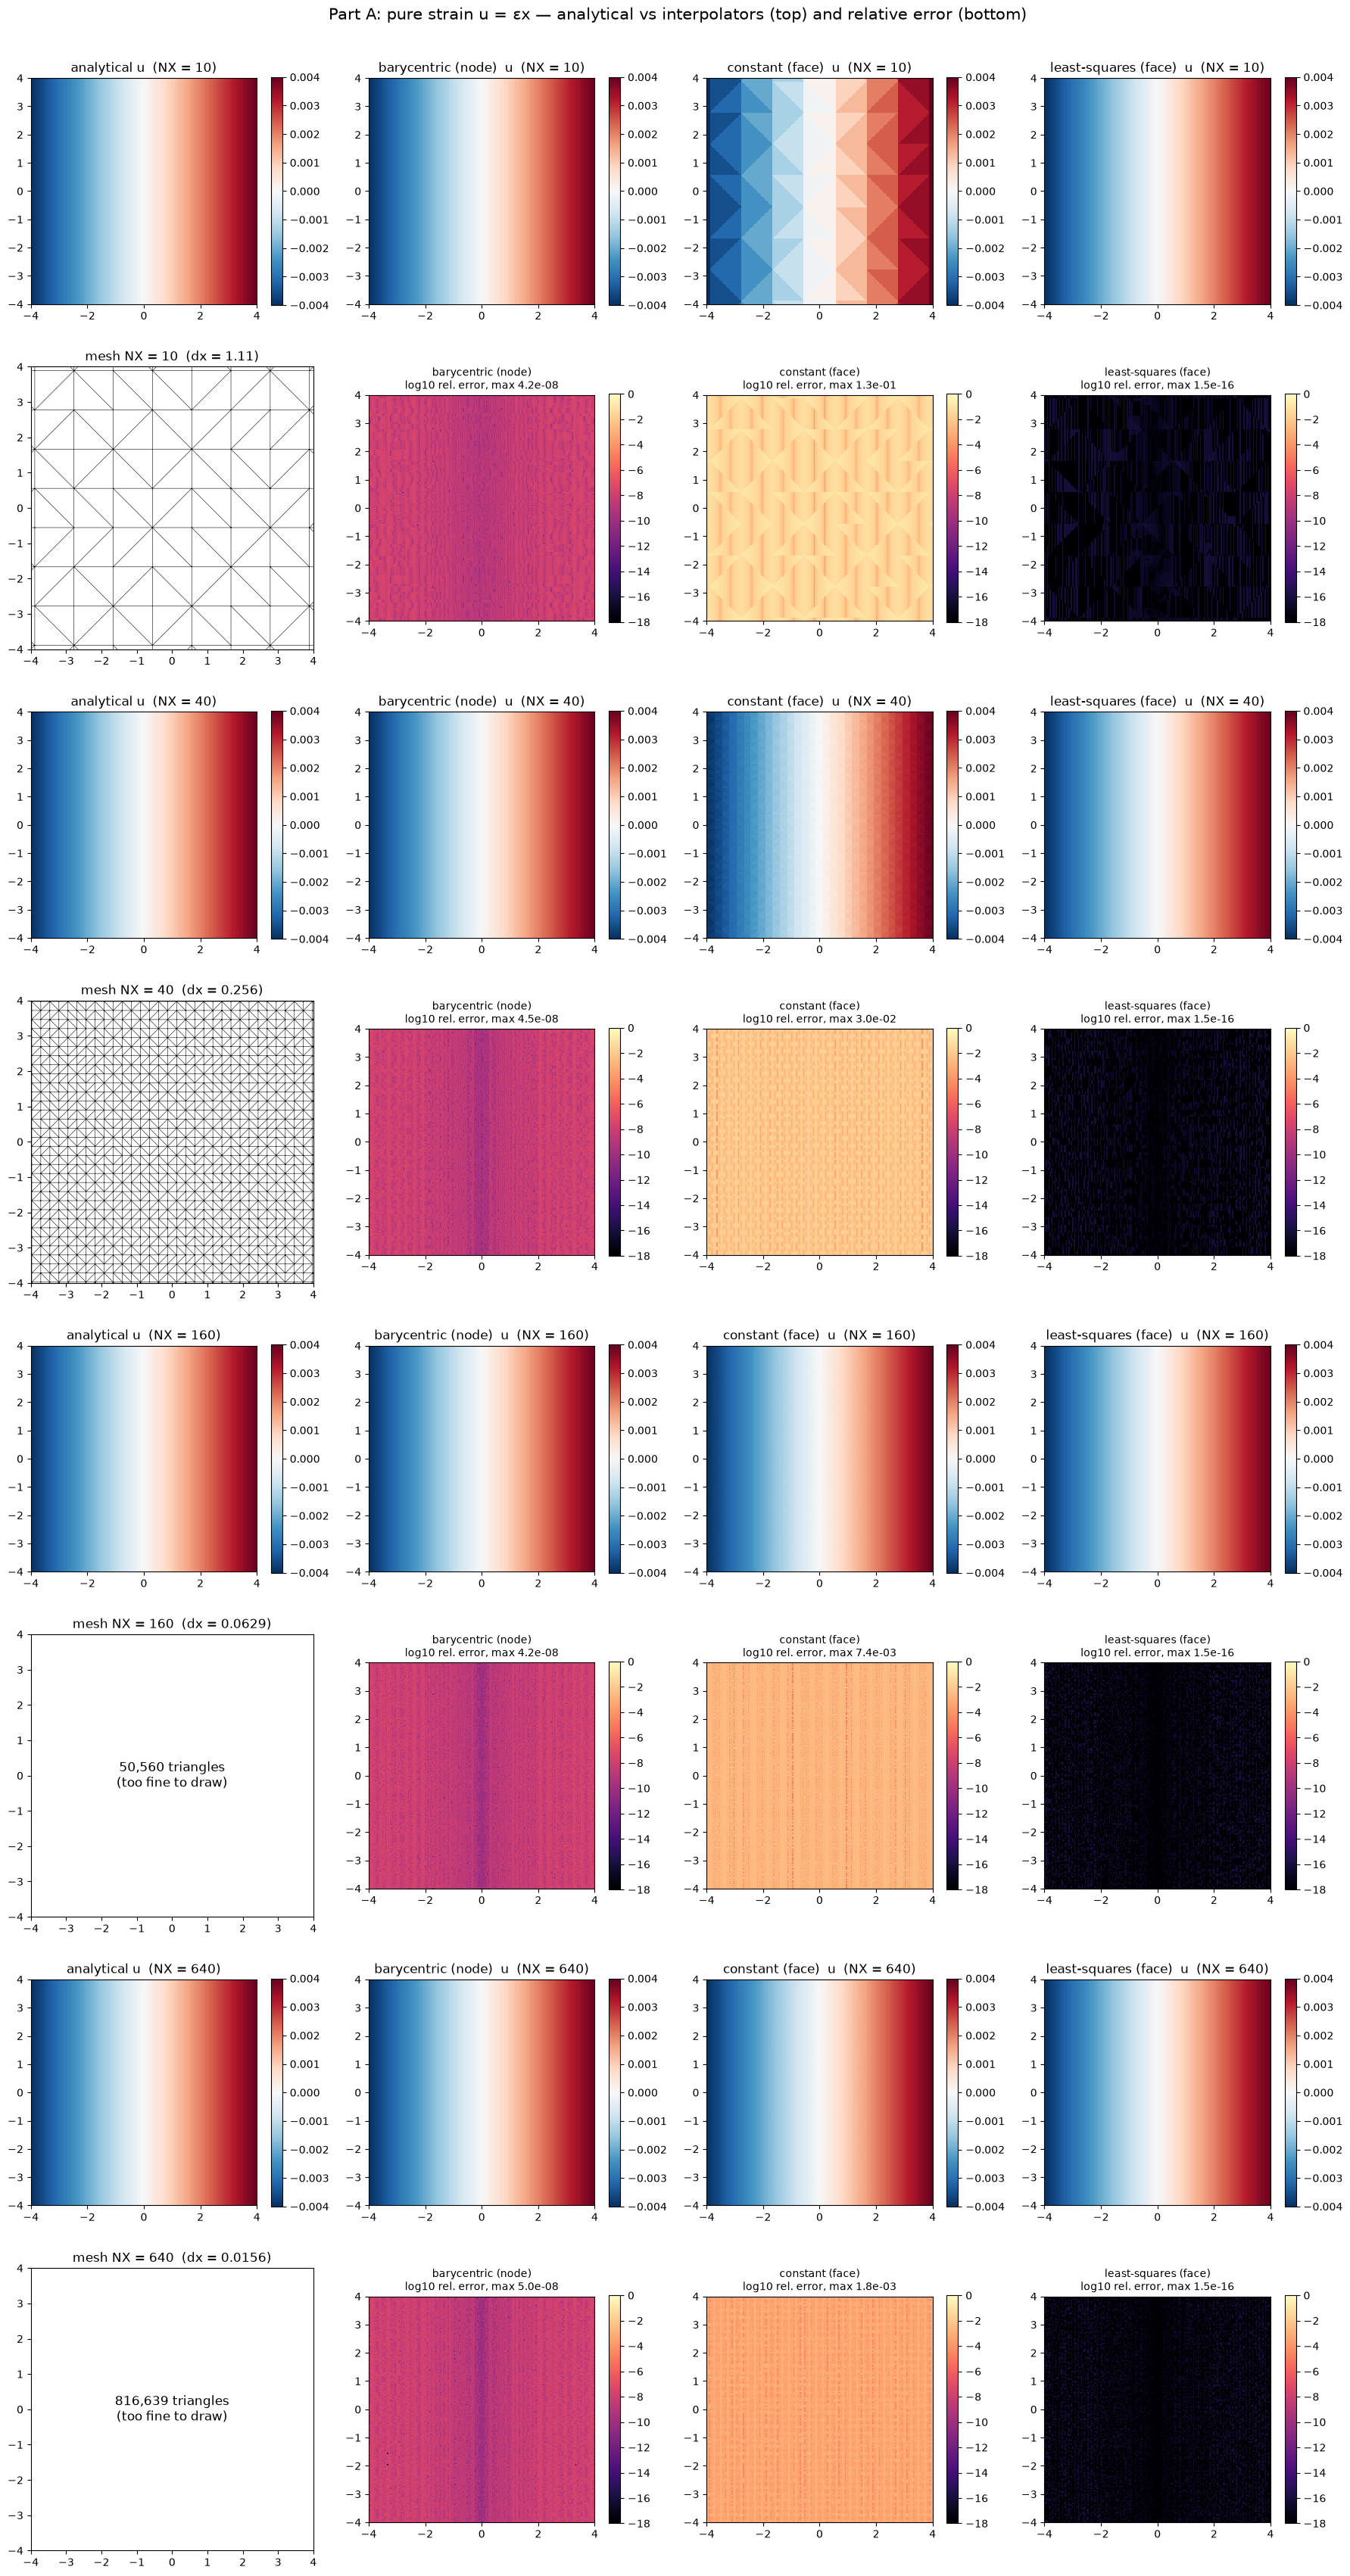

In [12]:
VIS_NX = [10, 40, 160, 640]
MAX_NX_DRAW_MESH = 40                            # finer meshes are not drawn (solid black, slow)
VIS_HALF = 4.0                                   # stay away from the dropped corner triangles
VIS_N = 240
XV, YV = np.meshgrid(np.linspace(-VIS_HALF, VIS_HALF, VIS_N), np.linspace(-VIS_HALF, VIS_HALF, VIS_N))
Y_LINE = 0.37
X_LINE = np.linspace(-VIS_HALF, VIS_HALF, 2001)


def eval_uv(fieldset, x, y):
    # Interpolated (u, v) at arbitrary points; NaN where the grid search finds no face.
    x, y = np.ravel(x), np.ravel(y)
    z = np.full_like(x, 0.5)
    fi = fieldset.fields["U"].grid.search(z, y, x)["FACE"]["index"]
    u = np.where(fi >= 0, fieldset.fields["U"].eval(0.0, z, y, x), np.nan)
    v = np.where(fi >= 0, fieldset.fields["V"].eval(0.0, z, y, x), np.nan)
    return u, v


def trajectories(fieldset, x0, y0, t_total_s, dt_s, chunk_s):
    # RK4 positions every chunk_s seconds -> arrays (n_out, n_particles).
    pset = parcels.ParticleSet(fieldset, pclass=Particle64, x=x0.copy(), y=y0.copy())
    xs_t, ys_t = [x0.copy()], [y0.copy()]
    for _ in range(int(round(t_total_s / chunk_s))):
        pset.execute(parcels.kernels.AdvectionRK4, runtime=np.timedelta64(int(chunk_s * 1000), "ms"),
                     dt=np.timedelta64(int(dt_s * 1000), "ms"), verbose_progress=False)
        xs_t.append(np.array(pset.x)); ys_t.append(np.array(pset.y))
    return np.array(xs_t), np.array(ys_t)


def mesh_triangulation(nx):
    g = GRIDS[nx]
    return mtri.Triangulation(g.node_lon.values, g.node_lat.values, triangles=g.face_node_connectivity.values)


def field_maps(uv_func, title, cmap="RdBu_r"):
    # Rows: per VIS_NX -> [analytical u, 3 schemes u] and [mesh, 3 schemes log10 rel error].
    u_ex = uv_func(XV, YV)[0]
    u_ref = np.nanmax(np.hypot(*uv_func(XV, YV)))
    vmax = np.nanmax(np.abs(u_ex))
    fig, axes = plt.subplots(2 * len(VIS_NX), 4, figsize=(18, 8.5 * len(VIS_NX)))
    for r, nx in enumerate(VIS_NX):
        ds_node, ds_face = make_dataset(GRIDS[nx], uv_func, "node"), make_dataset(GRIDS[nx], uv_func, "face")
        tri = mesh_triangulation(nx)
        ax = axes[2 * r, 0]
        im = ax.pcolormesh(XV, YV, u_ex, cmap=cmap, vmin=-vmax, vmax=vmax, shading="auto")
        ax.set_title(f"analytical u  (NX = {nx})")
        fig.colorbar(im, ax=ax, shrink=0.8)
        if nx <= MAX_NX_DRAW_MESH:
            axes[2 * r + 1, 0].triplot(tri, "k-", lw=0.4)
        else:
            axes[2 * r + 1, 0].text(0, 0, f"{GRIDS[nx].n_face:,} triangles\n(too fine to draw)", ha="center",
                                    va="center", fontsize=12)
        axes[2 * r + 1, 0].set_title(f"mesh NX = {nx}  (dx = {DX[nx]:.3g})")
        for c, scheme in enumerate(SCHEMES, start=1):
            u, _ = eval_uv(make_fieldset(scheme, ds_node, ds_face), XV, YV)
            u = u.reshape(XV.shape)
            ax = axes[2 * r, c]
            im = ax.pcolormesh(XV, YV, u, cmap=cmap, vmin=-vmax, vmax=vmax, shading="auto")
            ax.set_title(f"{scheme}  u  (NX = {nx})")
            fig.colorbar(im, ax=ax, shrink=0.8)
            ax = axes[2 * r + 1, c]
            err = np.abs(u - u_ex) / u_ref
            im = ax.pcolormesh(XV, YV, np.log10(np.maximum(err, 1e-18)), cmap="magma", vmin=-18, vmax=0,
                               shading="auto")
            ax.set_title(f"{scheme}\nlog10 rel. error, max {np.nanmax(err):.1e}", fontsize=10)
            fig.colorbar(im, ax=ax, shrink=0.8)
    for ax in axes.ravel():
        ax.set_aspect("equal"); ax.set_xlim(-VIS_HALF, VIS_HALF); ax.set_ylim(-VIS_HALF, VIS_HALF)
    fig.suptitle(title, fontsize=15, y=1.0)
    plt.tight_layout(); plt.show()


def transect(uv_func, title):
    u_ex = uv_func(X_LINE, np.full_like(X_LINE, Y_LINE))[0]
    u_ref = np.max(np.abs(u_ex))
    fig, axes = plt.subplots(2, len(VIS_NX), figsize=(6 * len(VIS_NX), 9), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
    for c, nx in enumerate(VIS_NX):
        ds_node, ds_face = make_dataset(GRIDS[nx], uv_func, "node"), make_dataset(GRIDS[nx], uv_func, "face")
        axes[0, c].plot(X_LINE, u_ex, "k-", lw=3, alpha=0.35, label="analytical")
        for scheme in SCHEMES:
            u, _ = eval_uv(make_fieldset(scheme, ds_node, ds_face), X_LINE, np.full_like(X_LINE, Y_LINE))
            axes[0, c].plot(X_LINE, u, color=SCHEME_COLORS[scheme], lw=1.3,
                            ls="--" if scheme == "least-squares (face)" else "-", label=scheme)
            axes[1, c].semilogy(X_LINE, np.maximum(np.abs(u - u_ex) / u_ref, 1e-18), color=SCHEME_COLORS[scheme],
                                lw=1, label=scheme)
        if nx <= MAX_NX_DRAW_MESH:
            node_x = GRIDS[nx].node_lon.values
            for xn in np.unique(np.round(node_x[np.abs(node_x) <= VIS_HALF], 10)):
                axes[0, c].axvline(xn, color="0.85", lw=0.6, zorder=0)
        axes[0, c].set_title(f"u along y = {Y_LINE}, NX = {nx}" + ("\n(grey: grid columns)" if nx <= MAX_NX_DRAW_MESH else ""))
        axes[0, c].set_ylabel("u"); axes[0, c].legend(fontsize=8)
        axes[1, c].axhline(EPS64, color="k", ls="--", lw=0.8)
        axes[1, c].set_ylim(1e-18, 2); axes[1, c].set_xlabel("x"); axes[1, c].set_ylabel("|u - u_exact| / max|u|")
        axes[1, c].grid(True, which="both", alpha=0.3)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()


field_maps(strain_uv, "Part A: pure strain u = εx — analytical vs interpolators (top) and relative error (bottom)")

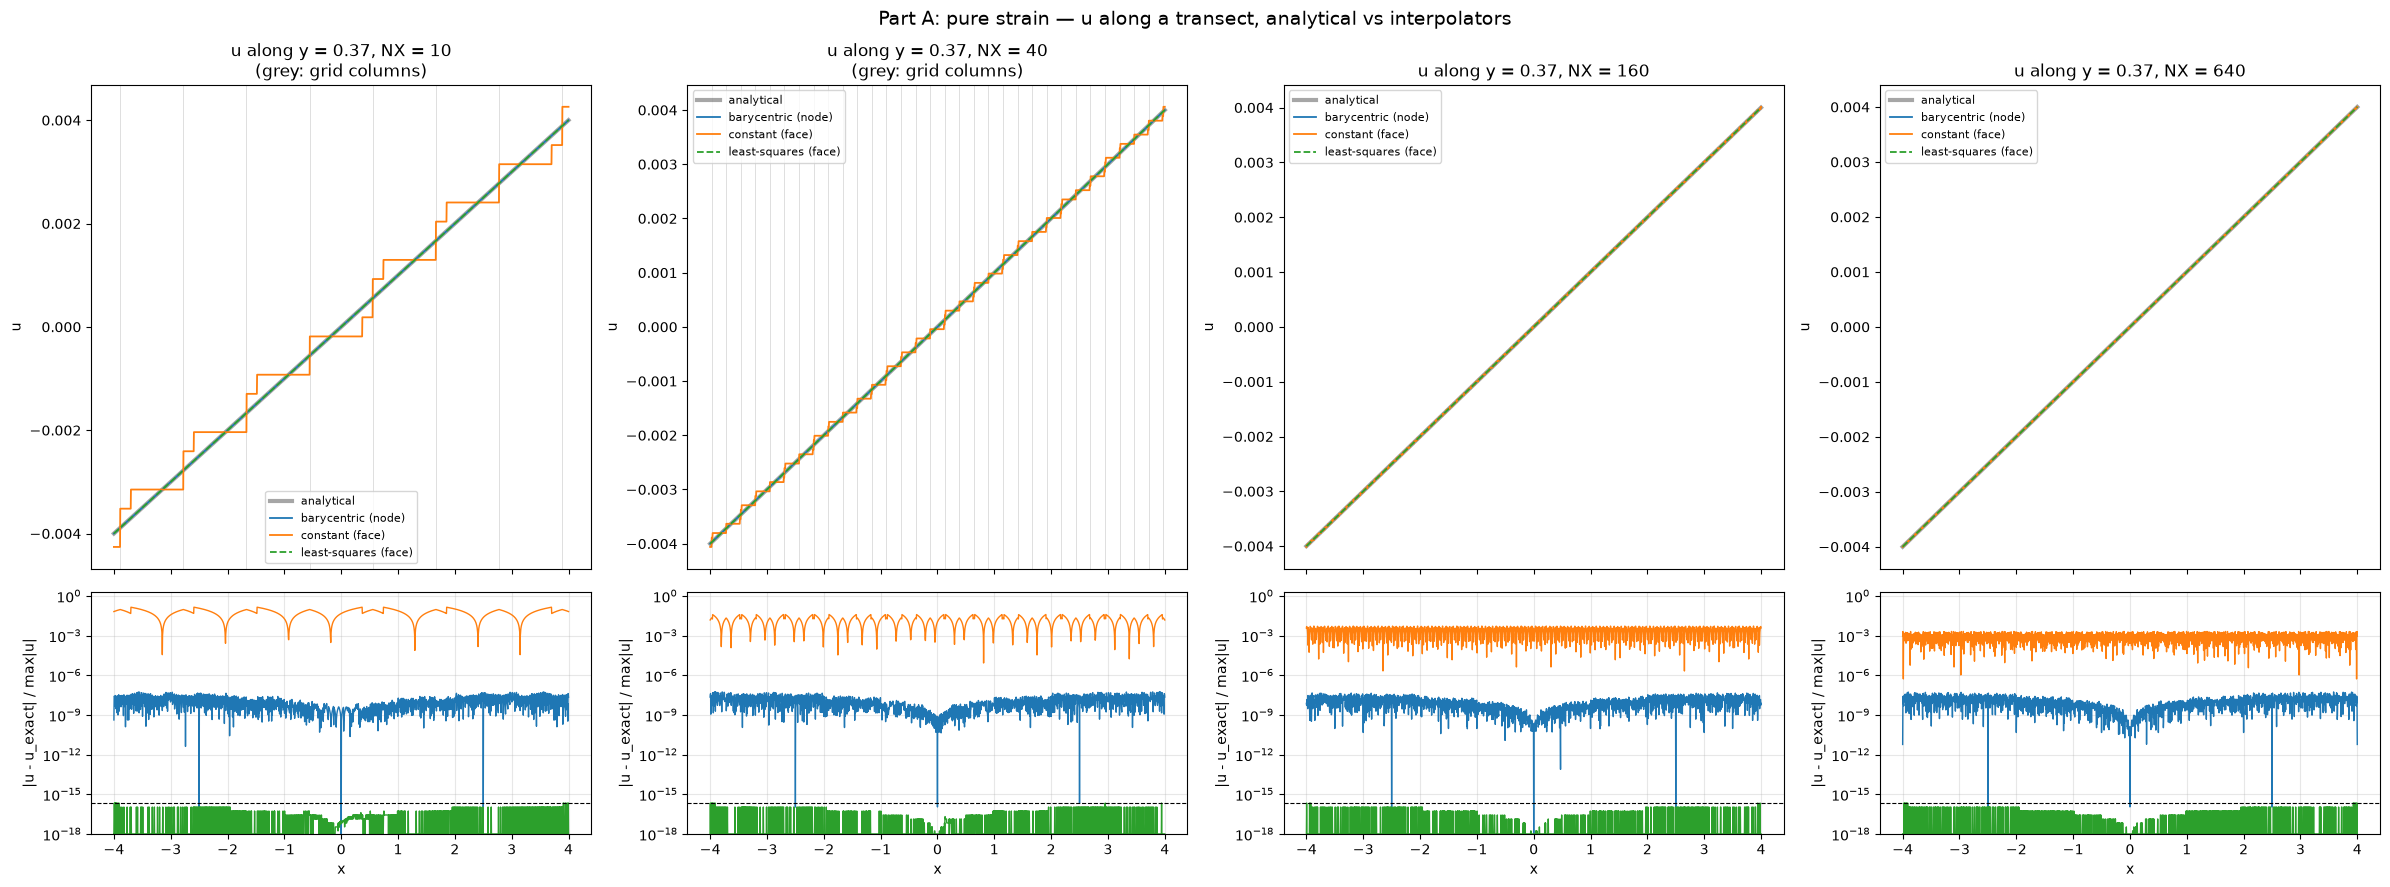

In [13]:
transect(strain_uv, "Part A: pure strain — u along a transect, analytical vs interpolators")

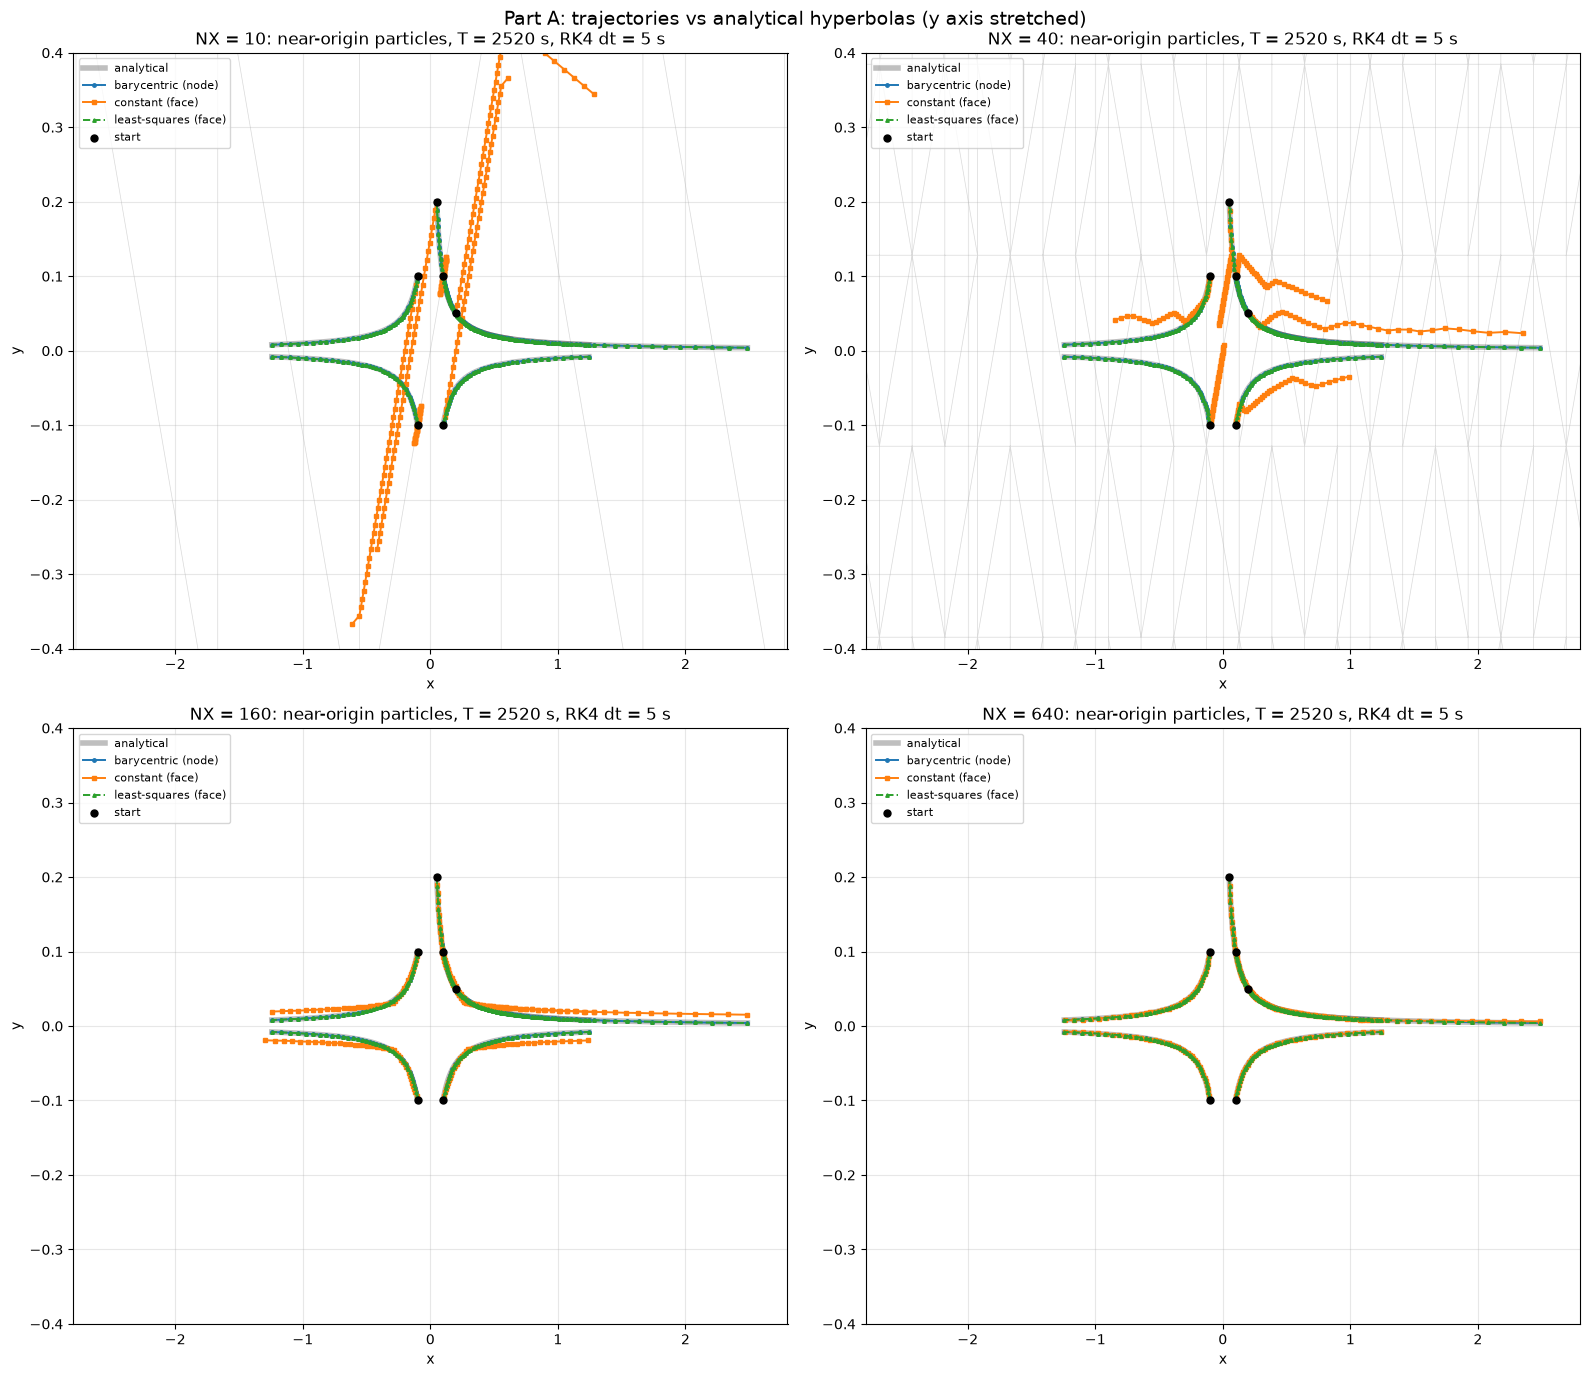

mean final error                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              2.791e-10       1.014e+00            1.760e-11   
40              1.824e-10       5.194e-01            1.760e-11   
160             1.385e-10       2.704e-02            1.760e-11   
640             1.894e-10       4.685e-03            1.760e-11   

          max final error                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              6.519e-10       1.249e+00            3.249e-11  
40              4.186e-10       1.251e+00            3.249e-11  
160             2.344e-10       5.396e-02            3.249e-11  
640             3.749e-10       1.104e-02            3.249e-11

In [14]:
T_VIS_A, DT_VIS_A, CHUNK_A = 2520.0, 5.0, 60.0
x0_near, y0_near = p_lon0[:6].copy(), p_lat0[:6].copy()
t_vis = np.arange(0, T_VIS_A + CHUNK_A / 2, CHUNK_A)
x_ex = x0_near[None, :] * np.exp(EPSILON * t_vis[:, None])
y_ex = y0_near[None, :] * np.exp(-EPSILON * t_vis[:, None])

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
traj_err_rows = []
for ax, nx in zip(axes.ravel(), VIS_NX):
    ds_node, ds_face = make_dataset(GRIDS[nx], strain_uv, "node"), make_dataset(GRIDS[nx], strain_uv, "face")
    if nx <= MAX_NX_DRAW_MESH:
        ax.triplot(mesh_triangulation(nx), color="0.85", lw=0.5, zorder=0)
    for i in range(len(x0_near)):
        ax.plot(x_ex[:, i], y_ex[:, i], "k-", lw=4, alpha=0.25, label="analytical" if i == 0 else None)
    for scheme in SCHEMES:
        xt, yt = trajectories(make_fieldset(scheme, ds_node, ds_face), x0_near, y0_near, T_VIS_A, DT_VIS_A, CHUNK_A)
        for i in range(len(x0_near)):
            ax.plot(xt[:, i], yt[:, i], color=SCHEME_COLORS[scheme], lw=1.4, marker=MARKERS[scheme], ms=2.5,
                    ls="--" if scheme == "least-squares (face)" else "-", label=scheme if i == 0 else None)
        err = np.hypot(xt[-1] - x_ex[-1], yt[-1] - y_ex[-1])
        traj_err_rows.append({"NX": nx, "scheme": scheme, "mean final error": err.mean(), "max final error": err.max()})
    ax.scatter(x0_near, y0_near, c="k", s=25, zorder=5, label="start")
    ax.set_xlim(-2.8, 2.8); ax.set_ylim(-0.4, 0.4)
    ax.set_title(f"NX = {nx}: near-origin particles, T = {T_VIS_A:.0f} s, RK4 dt = {DT_VIS_A:g} s")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)
fig.suptitle("Part A: trajectories vs analytical hyperbolas (y axis stretched)", fontsize=14)
plt.tight_layout(); plt.show()
pd.DataFrame(traj_err_rows).pivot(index="NX", columns="scheme", values=["mean final error", "max final error"])

#plot the stream function underneath

**What to look for (Part A).** The least-squares and barycentric fields are indistinguishable from the analytical
field at both resolutions (errors at round-off / Parcels' float32 floor), and their trajectories sit on the
analytical hyperbolas. The constant-face field is a mosaic of triangles; near the stagnation point a face can carry
the wrong sign of $u$ for a particle inside it, so near-origin particles can be pushed the wrong way or trapped
on the line $x \approx 0$ — the error that the T1-4b convergence study showed as a flat 1.25. Refining the grid
reduces the constant-face field error (first order) — compare the trajectory errors in the table for
$N_X = 10 \to 640$.

### Part A slopes and extrapolation to $10^{-16}$

Only the constant-face scheme has a resolution-dependent error for a linear field. Fitting
$\mathrm{err}=C\,\Delta x^{p}$ over $N_X\ge 80$ and solving $C\,\Delta x_*^{p}=10^{-16}$ gives the spacing that would be
needed to reach machine precision, with $N_X^* = 10/\Delta x_* + 1$.

In [15]:
def extrapolate(dx, err, target=1e-16):
    p, c = fit_slope(dx, err)
    with np.errstate(over="ignore", divide="ignore"):   # meaningless for the flat (exact / floor) curves
        dx_star = (target / c) ** (1.0 / p)
        nx_star = (LON_MAX - LON_MIN) / dx_star + 1
    return p, dx_star, nx_star


fit_rows_A = []
for scheme in SCHEMES:
    s = df_A[df_A["scheme"] == scheme]
    a = s[s["NX"] >= ASYMPTOTIC_NX]
    for metric in ["interp_max_rel", "interp_rms_rel", "traj_mean", "traj_max"]:
        p_all, _ = fit_slope(s["dx"].values, s[metric].values)
        p, dx_star, nx_star = extrapolate(a["dx"].values, a[metric].values)
        fit_rows_A.append({"scheme": scheme, "metric": metric, "slope (all NX)": p_all,
                           f"slope (NX>={ASYMPTOTIC_NX})": p,
                           "dx* for 1e-16": dx_star if scheme == "constant (face)" else np.nan,
                           "NX* for 1e-16": nx_star if scheme == "constant (face)" else np.nan})
df_fit_A = pd.DataFrame(fit_rows_A)
df_fit_A

,scheme,metric,slope (all NX),slope (NX>=80),dx* for 1e-16,NX* for 1e-16
0,barycentric (node),interp_max_rel,-4.490e-03,2.844e-02,NaN,NaN
1,barycentric (node),interp_rms_rel,2.287e-03,5.724e-03,NaN,NaN
2,barycentric (node),traj_mean,-1.716e-02,-5.926e-02,NaN,NaN
3,barycentric (node),traj_max,-2.524e-02,-9.277e-02,NaN,NaN
4,constant (face),interp_max_rel,9.985e-01,9.997e-01,6.566e-16,1.523e+16
5,constant (face),interp_rms_rel,9.963e-01,1.004e+00,1.669e-15,5.990e+15
6,constant (face),traj_mean,1.477e+00,1.790e+00,2.643e-09,3.783e+09
7,constant (face),traj_max,1.343e+00,1.458e+00,2.510e-11,3.984e+11
8,least-squares (face),interp_max_rel,1.163e-02,2.961e-05,NaN,NaN
9,least-squares (face),interp_rms_rel,1.063e-02,3.787e-03,NaN,NaN


In [16]:
cf = df_fit_A[(df_fit_A["scheme"] == "constant (face)") & (df_fit_A["metric"] == "interp_max_rel")].iloc[0]
print(f"constant (face), direct max relative error: slope {cf[f'slope (NX>={ASYMPTOTIC_NX})']:.2f}")
print(f"  to reach 1e-16 it would need dx* = {cf['dx* for 1e-16']:.1e} deg, NX* = {cf['NX* for 1e-16']:.1e}, "
      f"i.e. ~{cf['NX* for 1e-16'] ** 2:.0e} nodes / ~{2 * cf['NX* for 1e-16'] ** 2:.0e} triangles.")
print(f"  For comparison, the float64 spacing of the coordinate x = 5 itself is {np.spacing(5.0):.1e}: "
      f"dx* is {'below' if cf['dx* for 1e-16'] < np.spacing(5.0) else 'above'} it, so such a grid cannot even be "
      f"represented in float64.")

constant (face), direct max relative error: slope 1.00
  to reach 1e-16 it would need dx* = 6.6e-16 deg, NX* = 1.5e+16, i.e. ~2e+32 nodes / ~5e+32 triangles.
  For comparison, the float64 spacing of the coordinate x = 5 itself is 8.9e-16: dx* is below it, so such a grid cannot even be represented in float64.


**Interpretation (Part A).**

* **least-squares (face)** reproduces the linear field to float64 round-off at *every* resolution: the relative velocity
  error is $O(10^{-16})$ and the trajectory error after 720 RK4 steps is a few $10^{-16}$–$10^{-15}$ deg, i.e. a few
  units in the last place (ulp) of the positions. There is nothing left to converge: this is machine precision.
* **barycentric (node)** is flat at a relative error of order the float32 epsilon. This is the Parcels float32
  barycentric-weight limitation described at the top (**Parcels float32 limitation**, not a property of linear
  interpolation): the trajectory error ($\sim10^{-10}$–$10^{-9}$ deg) does not improve with resolution either.
* **constant (face)** converges at first order. Reaching $10^{-16}$ by refinement alone would require a node spacing
  smaller than the float64 resolution of the coordinates themselves — i.e. it is unreachable; machine precision can only be
  obtained with a scheme that is exact for the field (least-squares here).

## 6. Part B — Smooth nonlinear field: true spatial convergence orders

$$u = U_0\sin kx\cos ky,\qquad v = -U_0\cos kx\sin ky,\qquad k = 2\pi/5$$

(divergence-free cellular flow, two wavelengths across the domain). No scheme is exact for it, so the direct
interpolation error now shows each scheme's genuine order: ~1 (constant face) and ~2 (barycentric node and least-squares,
both linear reconstructions). Errors are relative to $\max|\mathbf{u}| = U_0$ over the sample points.

In [17]:
rows_B = []
for nx in NX_VALUES:
    ds_node = make_dataset(GRIDS[nx], cellular_uv, "node")
    ds_face = make_dataset(GRIDS[nx], cellular_uv, "face")
    for scheme in SCHEMES:
        d = direct_error(make_fieldset(scheme, ds_node, ds_face), cellular_uv)
        rows_B.append({"NX": nx, "dx": DX[nx], "scheme": scheme, **{f"interp_{k}": v for k, v in d.items()}})
df_B = pd.DataFrame(rows_B)
df_B.pivot(index="NX", columns="scheme", values=["interp_max_rel", "interp_rms_rel"])

interp_max_rel                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              5.758e-01       9.572e-01            9.431e-01   
20              1.466e-01       4.682e-01            2.478e-01   
40              3.633e-02       2.290e-01            5.896e-02   
80              8.844e-03       1.142e-01            1.450e-02   
160             2.200e-03       5.692e-02            3.678e-03   
320             5.469e-04       2.742e-02            8.950e-04   
640             1.352e-04       1.446e-02            2.185e-04   

           interp_rms_rel                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              2.446e-01       3.133e-01            1.661e-01  
20              6.016e-02       1.573e-01            4.155e-02  
40              1.468e-02       7.664e-02            1.007e-02  
80              3.599e-03       3.792e-02            2.463e-03  
160             8.946e-04       1.893e-02            6.116e-04  
320             2.225e-04       9.276e-03            1.500e-04  
640             5.538e-05       4.644e-03            3.736e-05

In [18]:
fit_rows_B = []
for scheme in SCHEMES:
    s = df_B[df_B["scheme"] == scheme]
    a = s[s["NX"] >= ASYMPTOTIC_NX]
    for metric in ["interp_max_rel", "interp_rms_rel"]:
        p_all, _ = fit_slope(s["dx"].values, s[metric].values)
        p, dx_star, nx_star = extrapolate(a["dx"].values, a[metric].values)
        fit_rows_B.append({"scheme": scheme, "metric": metric, "slope (all NX)": p_all,
                           f"slope (NX>={ASYMPTOTIC_NX})": p, "dx* for 1e-16": dx_star, "NX* for 1e-16": nx_star})
df_fit_B = pd.DataFrame(fit_rows_B)
df_fit_B

,scheme,metric,slope (all NX),slope (NX>=80),dx* for 1e-16,NX* for 1e-16
0,barycentric (node),interp_max_rel,1.969e+00,2.000e+00,1.342e-08,7.454e+08
1,barycentric (node),interp_rms_rel,1.975e+00,1.997e+00,2.059e-08,4.857e+08
2,constant (face),interp_max_rel,9.904e-01,9.944e-01,9.179e-17,1.089e+17
3,constant (face),interp_rms_rel,9.928e-01,1.007e+00,4.145e-16,2.413e+16
4,least-squares (face),interp_max_rel,1.973e+00,2.009e+00,1.124e-08,8.893e+08
5,least-squares (face),interp_rms_rel,1.978e+00,2.005e+00,2.649e-08,3.774e+08


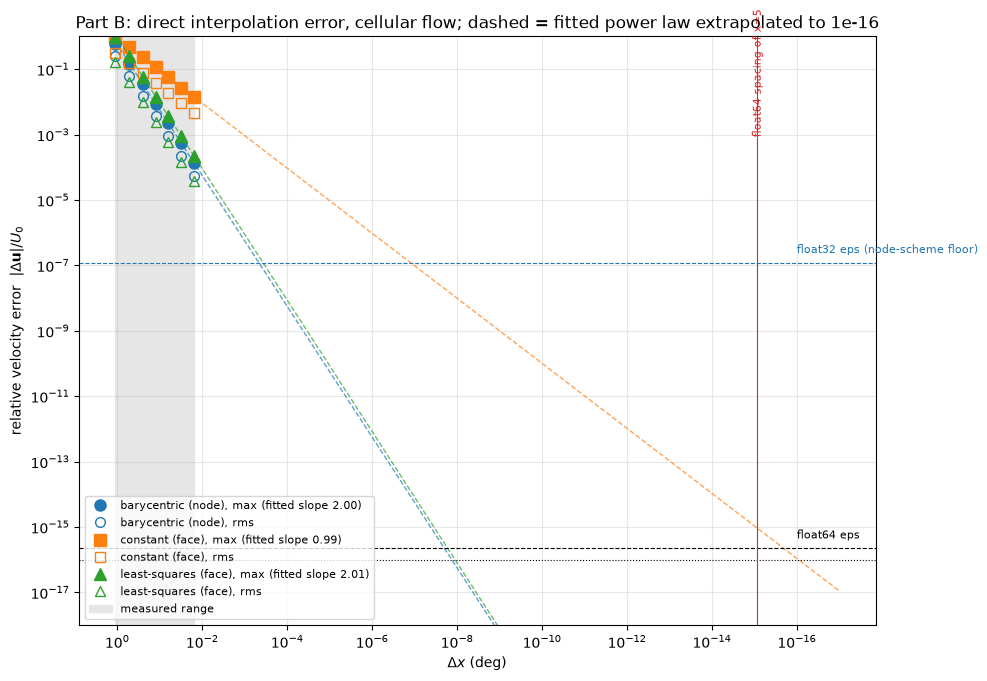

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))
dx_ext = np.logspace(np.log10(dxs[0]), -17, 200)
for scheme in SCHEMES:
    s = df_B[df_B["scheme"] == scheme]
    a = s[s["NX"] >= ASYMPTOTIC_NX]
    p, c = fit_slope(a["dx"].values, a["interp_max_rel"].values)
    ax.loglog(s["dx"], s["interp_max_rel"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=2, ls="none",
              ms=8, label=f"{scheme}, max (fitted slope {p:.2f})")
    ax.loglog(s["dx"], s["interp_rms_rel"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], ls="none",
              mfc="none", ms=7, label=f"{scheme}, rms")
    ax.loglog(dx_ext, c * dx_ext ** p, color=SCHEME_COLORS[scheme], lw=1, ls="--", alpha=0.7)
ax.axhline(EPS64, color="k", ls="--", lw=0.8)
ax.text(1e-16, EPS64 * 2, "float64 eps", fontsize=8)
ax.axhline(1e-16, color="k", ls=":", lw=0.8)
ax.axhline(EPS32, color="C0", ls="--", lw=0.8)
ax.text(1e-16, EPS32 * 2, "float32 eps (node-scheme floor)", fontsize=8, color="C0")
ax.axvline(np.spacing(5.0), color="C3", lw=0.8)
ax.text(np.spacing(5.0) * 1.3, 1e-3, "float64 spacing of x=5", rotation=90, fontsize=8, color="C3")
ax.axvspan(dxs[-1], dxs[0], color="0.9", zorder=0, label="measured range")
ax.set_xlabel(r"$\Delta x$ (deg)")
ax.set_ylabel(r"relative velocity error  $|\Delta\mathbf{u}|/U_0$")
ax.set_title("Part B: direct interpolation error, cellular flow; dashed = fitted power law extrapolated to 1e-16")
ax.set_ylim(1e-18, 1)
ax.invert_xaxis()
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

### Part B — Analytical vs interpolated: fields, transect and trajectories

Same views for the cellular flow. There is no closed-form trajectory, but the flow has a stream function
$$\psi = \frac{U_0}{k}\,\sin kx\,\sin ky,\qquad u = \partial_y\psi,\; v = -\partial_x\psi,$$
so every exact trajectory follows a contour of $\psi$ (closed orbits inside each cell). The trajectory panel
overlays computed RK4 paths (T = 6000 s, about one revolution of the inner orbits) on the analytical streamlines and
reports the drift $\max_t |\psi(\mathbf{x}(t)) - \psi(\mathbf{x}_0)| / (U_0/k)$.

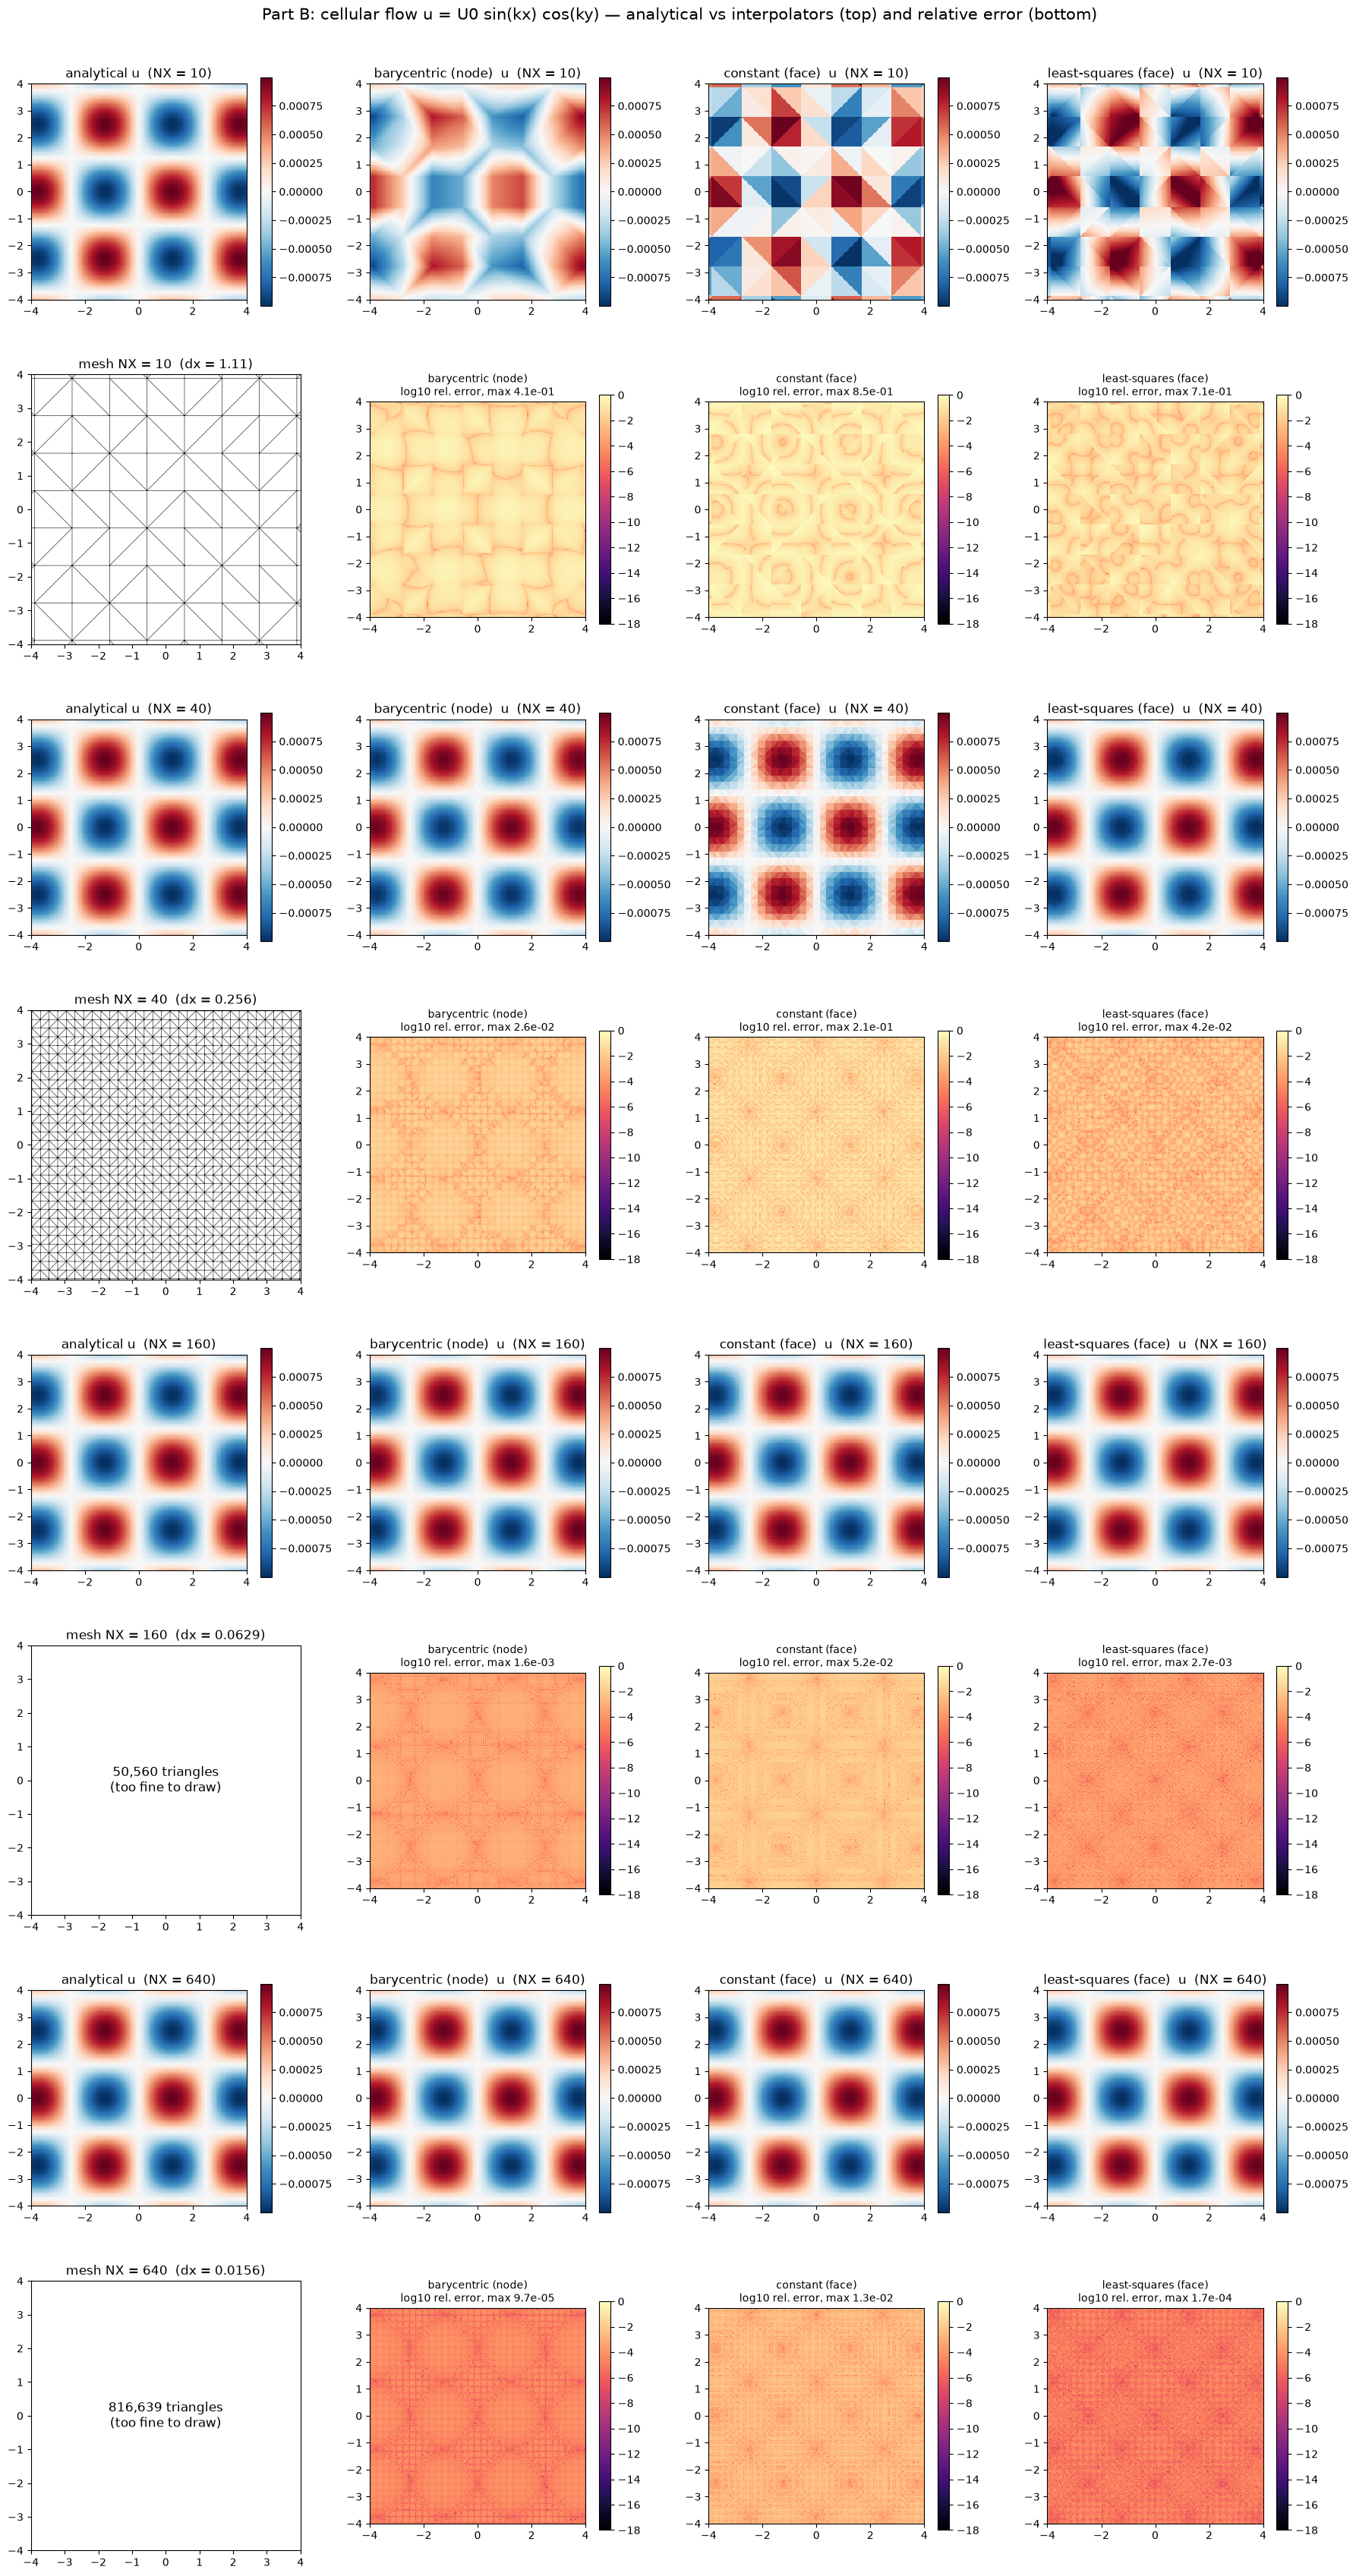

In [20]:
field_maps(cellular_uv, "Part B: cellular flow u = U0 sin(kx) cos(ky) — analytical vs interpolators (top) and relative error (bottom)")

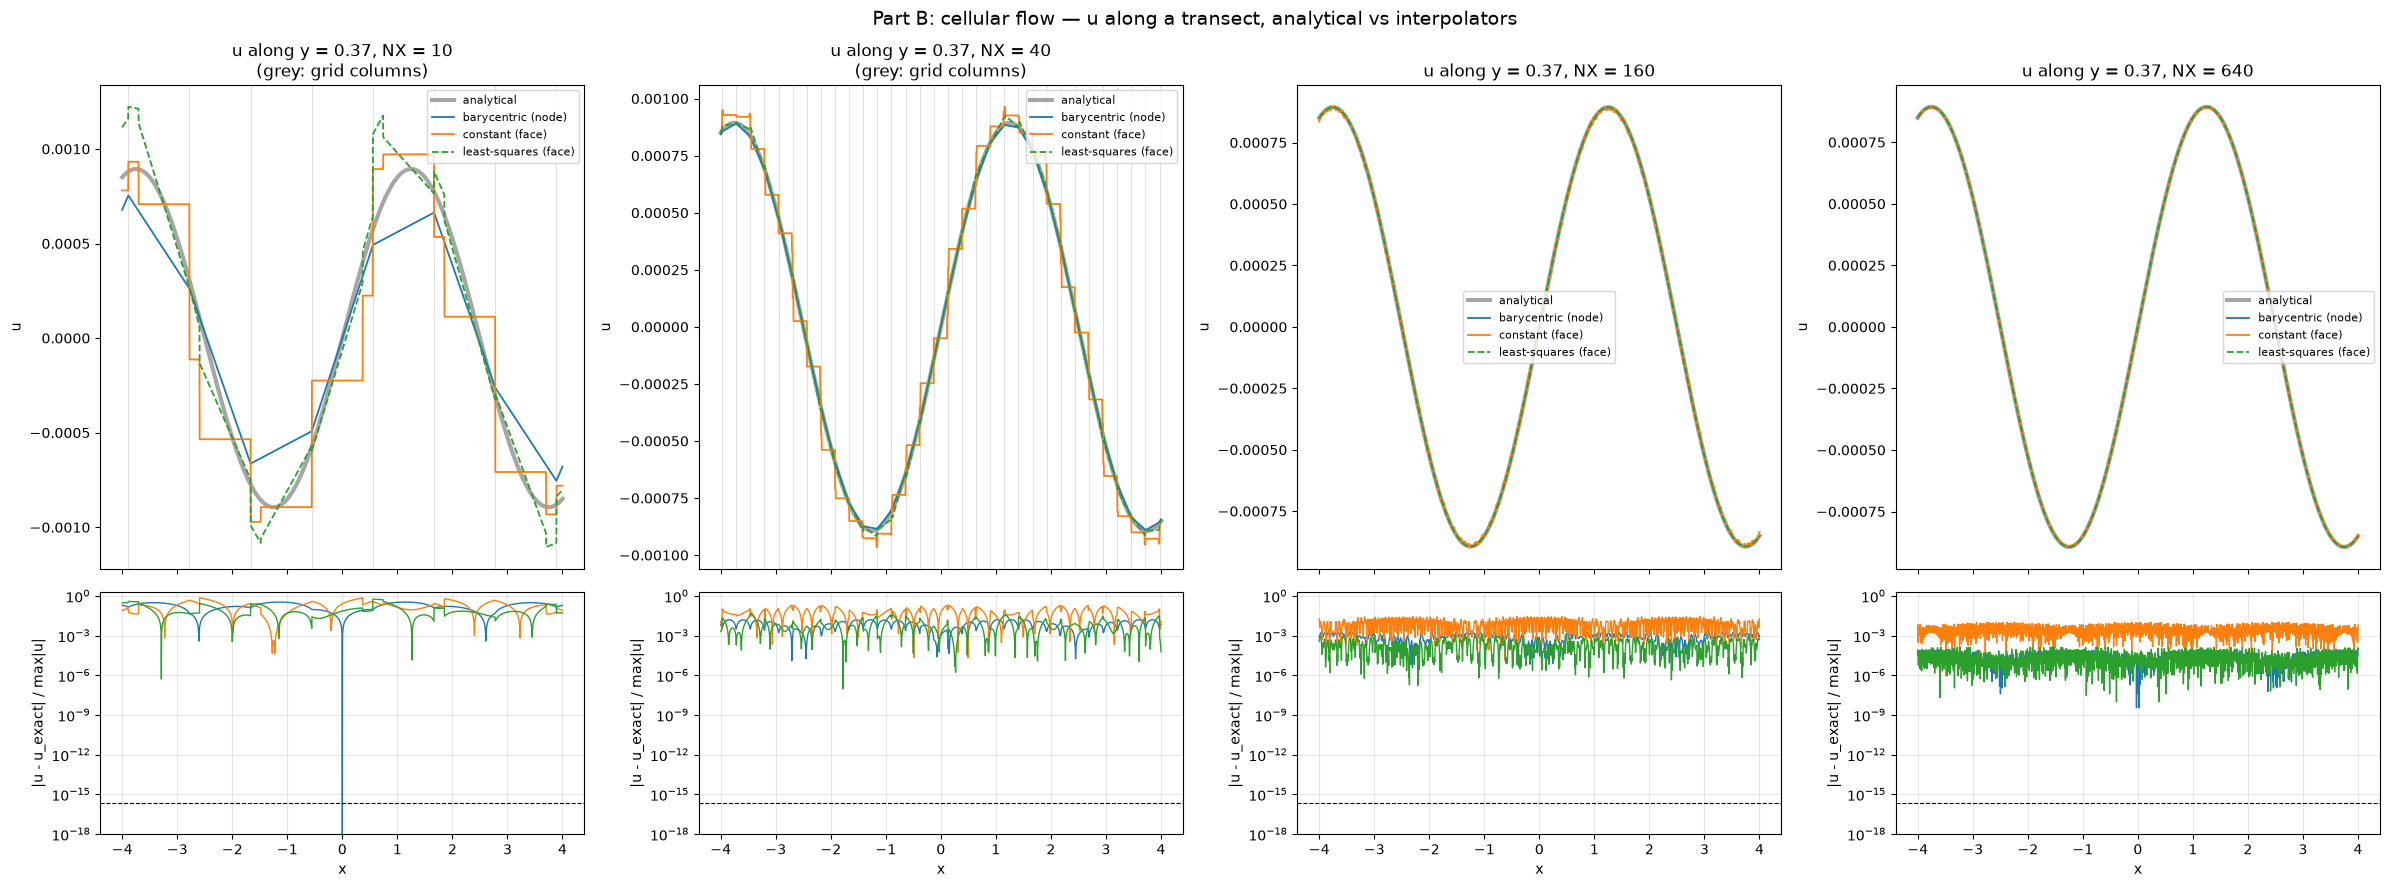

In [21]:
transect(cellular_uv, "Part B: cellular flow — u along a transect, analytical vs interpolators")

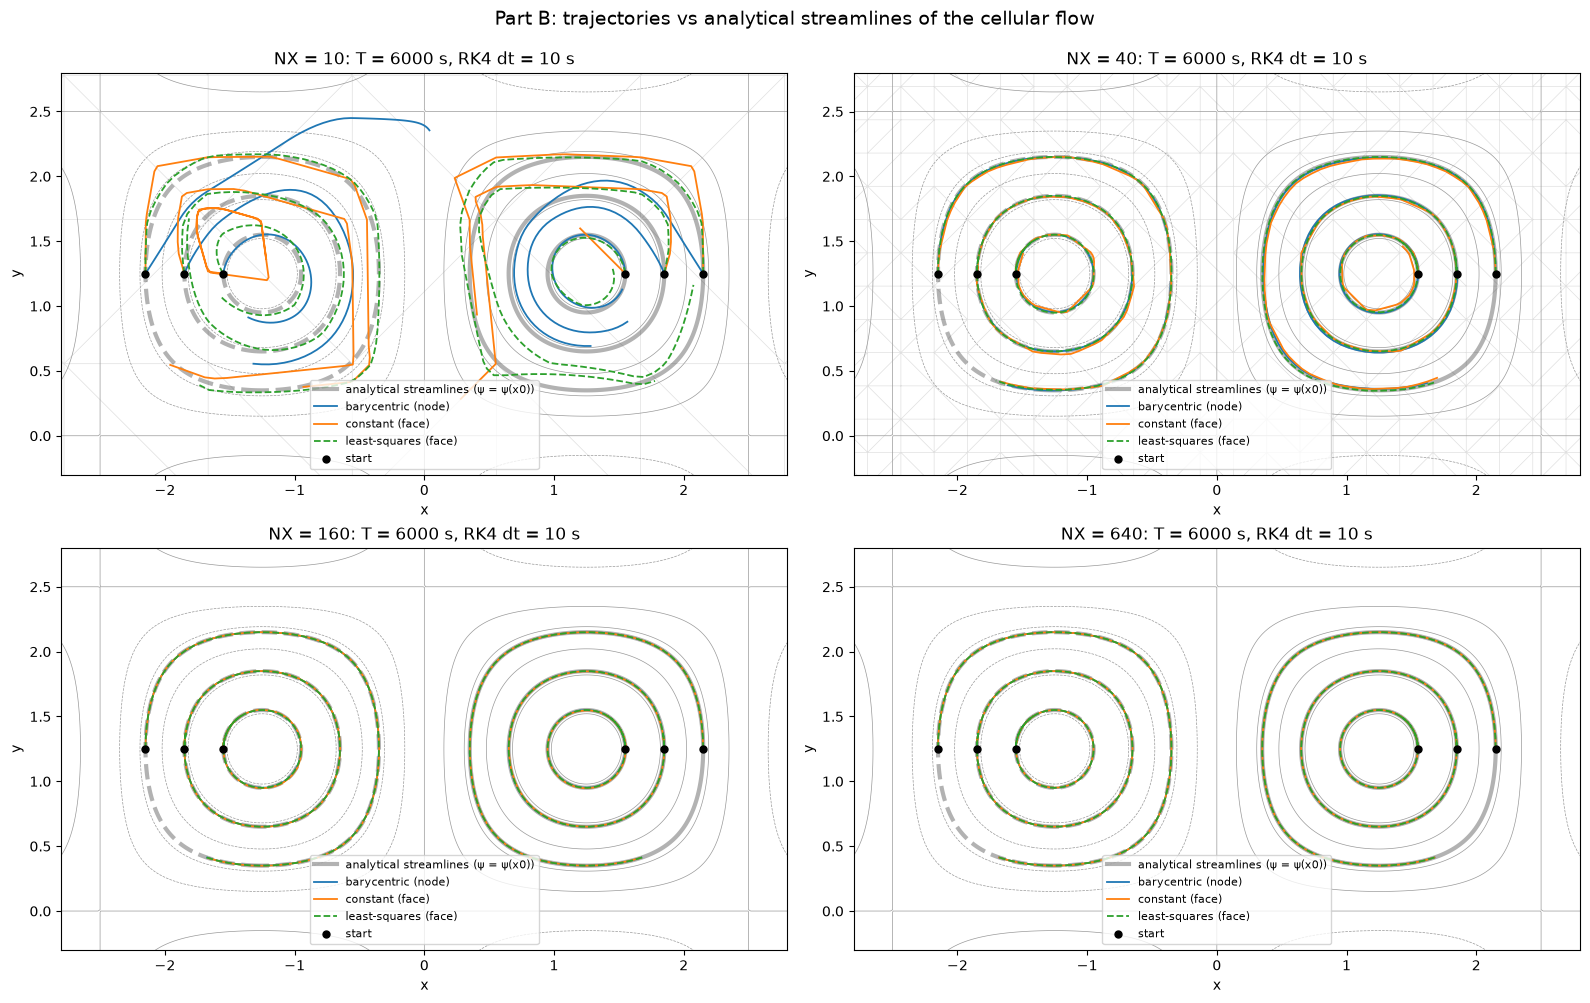

mean psi drift                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              1.789e-01       2.747e-01            1.264e-01   
40              5.771e-03       1.795e-02            2.577e-03   
160             1.244e-04       2.069e-03            5.182e-05   
640             4.265e-06       3.529e-04            2.638e-06   

            max psi drift                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              4.348e-01       6.079e-01            2.968e-01  
40              1.337e-02       2.533e-02            5.334e-03  
160             2.448e-04       2.870e-03            8.994e-05  
640             8.857e-06       5.657e-04            6.915e-06

In [22]:
def psi(x, y):
    return (U0 / K_WAVE) * np.sin(K_WAVE * x) * np.sin(K_WAVE * y)


T_VIS_B, DT_VIS_B, CHUNK_B = 6000.0, 10.0, 100.0
# two cells: centred at (1.25, 1.25) (psi > 0) and (-1.25, 1.25) (psi < 0); three orbits each
offs = np.array([0.3, 0.6, 0.9])
x0_B = np.concatenate([1.25 + offs, -1.25 - offs])
y0_B = np.full(x0_B.size, 1.25)
psi_scale = U0 / K_WAVE

XS, YS = np.meshgrid(np.linspace(-VIS_HALF, VIS_HALF, 400), np.linspace(-VIS_HALF, VIS_HALF, 400))
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
psi_rows = []
for ax, nx in zip(axes.ravel(), VIS_NX):
    ds_node, ds_face = make_dataset(GRIDS[nx], cellular_uv, "node"), make_dataset(GRIDS[nx], cellular_uv, "face")
    if nx <= MAX_NX_DRAW_MESH:
        ax.triplot(mesh_triangulation(nx), color="0.88", lw=0.5, zorder=0)
    ax.contour(XS, YS, psi(XS, YS), levels=np.unique(np.round(psi(x0_B, y0_B), 12)), colors="k", linewidths=3,
               alpha=0.3)
    ax.contour(XS, YS, psi(XS, YS), levels=12, colors="0.6", linewidths=0.5)
    ax.plot([], [], "k-", lw=3, alpha=0.3, label="analytical streamlines (ψ = ψ(x0))")
    for scheme in SCHEMES:
        xt, yt = trajectories(make_fieldset(scheme, ds_node, ds_face), x0_B, y0_B, T_VIS_B, DT_VIS_B, CHUNK_B)
        for i in range(x0_B.size):
            ax.plot(xt[:, i], yt[:, i], color=SCHEME_COLORS[scheme], lw=1.3,
                    ls="--" if scheme == "least-squares (face)" else "-", label=scheme if i == 0 else None)
        drift = np.max(np.abs(psi(xt, yt) - psi(x0_B, y0_B)[None, :]), axis=0) / psi_scale
        psi_rows.append({"NX": nx, "scheme": scheme, "mean psi drift": drift.mean(), "max psi drift": drift.max()})
    ax.scatter(x0_B, y0_B, c="k", s=25, zorder=5, label="start")
    ax.set_xlim(-2.8, 2.8); ax.set_ylim(-0.3, 2.8); ax.set_aspect("equal")
    ax.set_title(f"NX = {nx}: T = {T_VIS_B:.0f} s, RK4 dt = {DT_VIS_B:g} s")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8, loc="lower center")
fig.suptitle("Part B: trajectories vs analytical streamlines of the cellular flow", fontsize=14, y=0.995)
plt.tight_layout(); plt.show()
pd.DataFrame(psi_rows).pivot(index="NX", columns="scheme", values=["mean psi drift", "max psi drift"])

**What to look for (Part B).** None of the schemes is exact here. On the coarse grid the constant-face field is
visibly blocky and its trajectories spiral off the streamlines; the two linear schemes follow the analytical field
and streamlines much more closely, and all three improve as $N_X$ goes from 10 to 640 — the first-order vs
second-order convergence quantified in the plot above (see the $\psi$-drift table).

**Interpretation (Part B).** On a field that none of the schemes represents exactly, the errors decay algebraically:
first order for the constant-face scheme and second order for the two linear reconstructions. Such an error only
approaches machine precision asymptotically; the extrapolated spacings $\Delta x_*$ needed for $10^{-16}$ are far below
any practical grid (and, for first order, below the float64 spacing of the coordinates). In practice the barycentric
node scheme would in addition stall at its float32 floor (~$10^{-7}$ relative) long before that — on the grids used here
its second-order truncation error is still well above that floor, so the floor is not visible in Part B.

## 7. Results Summary

In [23]:
summary = df_A[["NX", "dx", "scheme", "interp_max_rel", "interp_rms_rel", "traj_mean", "traj_max", "wall_s"]].merge(
    df_B[["NX", "scheme", "interp_max_rel", "interp_rms_rel"]].rename(
        columns={"interp_max_rel": "B_interp_max_rel", "interp_rms_rel": "B_interp_rms_rel"}),
    on=["NX", "scheme"])
summary = summary.rename(columns={"interp_max_rel": "A_interp_max_rel", "interp_rms_rel": "A_interp_rms_rel",
                                  "traj_mean": "A_traj_mean", "traj_max": "A_traj_max", "wall_s": "A_traj_wall_s"})
summary.sort_values(["scheme", "NX"]).reset_index(drop=True)

,NX,dx,scheme,A_interp_max_rel,A_interp_rms_rel,A_traj_mean,A_traj_max,A_traj_wall_s,B_interp_max_rel,B_interp_rms_rel
0,10,1.111e+00,barycentric (node),6.346e-08,1.722e-08,3.014e-10,7.315e-10,1.698e+01,5.758e-01,2.446e-01
1,20,5.263e-01,barycentric (node),5.727e-08,1.713e-08,3.042e-10,6.880e-10,1.705e+01,1.466e-01,6.016e-02
2,40,2.564e-01,barycentric (node),5.743e-08,1.719e-08,3.016e-10,7.417e-10,1.686e+01,3.633e-02,1.468e-02
3,80,1.266e-01,barycentric (node),6.257e-08,1.716e-08,2.976e-10,6.863e-10,1.692e+01,8.844e-03,3.599e-03
4,160,6.289e-02,barycentric (node),6.472e-08,1.724e-08,3.027e-10,6.829e-10,1.737e+01,2.200e-03,8.946e-04
5,320,3.135e-02,barycentric (node),6.268e-08,1.705e-08,2.953e-10,7.926e-10,1.687e+01,5.469e-04,2.225e-04
6,640,1.565e-02,barycentric (node),5.919e-08,1.700e-08,3.443e-10,8.101e-10,1.738e+01,1.352e-04,5.538e-05
7,10,1.111e+00,constant (face),1.668e-01,7.268e-02,6.394e-02,1.769e-01,1.342e+01,9.572e-01,3.133e-01
8,20,5.263e-01,constant (face),7.912e-02,3.604e-02,3.412e-02,7.492e-02,1.318e+01,4.682e-01,1.573e-01
9,40,2.564e-01,constant (face),3.827e-02,1.744e-02,1.504e-02,6.057e-02,1.328e+01,2.290e-01,7.664e-02


## 8. Verification Assertions

Thresholds (fixed before running the sweep):

1. **least-squares, linear field, direct error** — relative error `< 1e-14` at every $N_X$. float64 eps is $2.2\times10^{-16}$;
   the reconstruction does $O(10)$ flops per point, so `1e-14` (~45 eps) allows for round-off but not for any
   truncation error.
2. **least-squares, linear field, trajectory** — max position error `< 1e-13` deg at every $N_X$. Worst-case linear
   accumulation of one ulp per step over 720 steps at $|x|\le4.3$ ($\mathrm{ulp}=8.9\times10^{-16}$) is $6\times10^{-13}$;
   `1e-13` is ~110 ulp of the largest position, and the time error at $\Delta t=0.5$ s is $\lesssim10^{-16}$ (Section 4).
3. **barycentric node, linear field** — relative direct error `< 1e-6` at every $N_X$, i.e. exact up to the float32
   weights (eps32 = $1.2\times10^{-7}$, times a factor < 10 for the 3-term sum).
   *Informational (not counted):* the error is flat with resolution (finest/coarsest within a factor 10), documenting
   the Parcels float32 floor; this check is expected to change once Parcels computes the weights in float64.
4. **constant face, linear field** — fitted slope ($N_X\ge80$) of the direct max and RMS relative errors, and of the mean
   trajectory error, within 0.3 of 1.
5. **nonlinear field orders** ($N_X\ge80$, max and RMS relative errors) — constant face within 0.3 of 1;
   barycentric node and least-squares within 0.3 of 2.
6. **ordering** — at every $N_X$ on the linear field: least-squares < barycentric node < constant face (direct max error).

In [24]:
all_pass = True
check_rows = []


def check(ok, msg, counted=True):
    global all_pass
    if counted:
        all_pass &= bool(ok)
    tag = ("PASS" if ok else "FAIL") if counted else ("INFO-yes" if ok else "INFO-no")
    check_rows.append({"check": msg, "result": tag})
    print(f"  [{tag}] {msg}")


def slope_of(df_fit, scheme, metric):
    return df_fit[(df_fit["scheme"] == scheme) & (df_fit["metric"] == metric)][f"slope (NX>={ASYMPTOTIC_NX})"].iloc[0]


A = {s: df_A[df_A["scheme"] == s].set_index("NX") for s in SCHEMES}

print("=== 1. least-squares, linear field: direct error at machine precision ===")
for nx in NX_VALUES:
    e = A["least-squares (face)"].loc[nx, "interp_max_rel"]
    check(e < 1e-14, f"NX={nx}: LSQ direct max rel error {e:.2e} < 1e-14")

print("\n=== 2. least-squares, linear field: trajectory error at round-off ===")
for nx in NX_VALUES:
    e = A["least-squares (face)"].loc[nx, "traj_max"]
    check(e < 1e-13, f"NX={nx}: LSQ trajectory max error {e:.2e} deg < 1e-13")

print("\n=== 3. barycentric node, linear field: exact up to float32 weights ===")
for nx in NX_VALUES:
    e = A["barycentric (node)"].loc[nx, "interp_max_rel"]
    check(e < 1e-6, f"NX={nx}: node direct max rel error {e:.2e} < 1e-6")
en = A["barycentric (node)"]["interp_max_rel"]
check(en.iloc[0] / en.iloc[-1] < 10,
      f"node error flat with NX (Parcels float32 floor): coarsest/finest = {en.iloc[0] / en.iloc[-1]:.2f} < 10",
      counted=False)

print("\n=== 4. constant face, linear field: first order ===")
for metric in ["interp_max_rel", "interp_rms_rel", "traj_mean"]:
    p = slope_of(df_fit_A, "constant (face)", metric)
    check(abs(p - 1) < 0.3, f"constant (face) {metric}: slope {p:.2f}, |p - 1| < 0.3")

print("\n=== 5. nonlinear field: convergence orders ===")
for scheme, expected in [("constant (face)", 1), ("barycentric (node)", 2), ("least-squares (face)", 2)]:
    for metric in ["interp_max_rel", "interp_rms_rel"]:
        p = slope_of(df_fit_B, scheme, metric)
        check(abs(p - expected) < 0.3, f"{scheme} {metric}: slope {p:.2f}, |p - {expected}| < 0.3")

print("\n=== 6. ordering on the linear field ===")
for nx in NX_VALUES:
    l, n, c = (A[s].loc[nx, "interp_max_rel"] for s in ["least-squares (face)", "barycentric (node)", "constant (face)"])
    check(l < n < c, f"NX={nx}: LSQ {l:.1e} < node {n:.1e} < constant {c:.1e}")

print()
if all_pass:
    print("T1-4c PASSED: all counted checks within tolerance.")
else:
    raise AssertionError("T1-4c FAILED: one or more checks exceeded tolerance (see FAIL lines above).")

=== 1. least-squares, linear field: direct error at machine precision ===
  [PASS] NX=10: LSQ direct max rel error 1.81e-16 < 1e-14
  [PASS] NX=20: LSQ direct max rel error 1.97e-16 < 1e-14
  [PASS] NX=40: LSQ direct max rel error 1.77e-16 < 1e-14
  [PASS] NX=80: LSQ direct max rel error 1.81e-16 < 1e-14
  [PASS] NX=160: LSQ direct max rel error 1.76e-16 < 1e-14
  [PASS] NX=320: LSQ direct max rel error 1.76e-16 < 1e-14
  [PASS] NX=640: LSQ direct max rel error 1.81e-16 < 1e-14

=== 2. least-squares, linear field: trajectory error at round-off ===
  [PASS] NX=10: LSQ trajectory max error 3.11e-15 deg < 1e-13
  [PASS] NX=20: LSQ trajectory max error 3.11e-15 deg < 1e-13
  [PASS] NX=40: LSQ trajectory max error 3.11e-15 deg < 1e-13
  [PASS] NX=80: LSQ trajectory max error 3.11e-15 deg < 1e-13
  [PASS] NX=160: LSQ trajectory max error 3.11e-15 deg < 1e-13
  [PASS] NX=320: LSQ trajectory max error 3.11e-15 deg < 1e-13
  [PASS] NX=640: LSQ trajectory max error 3.11e-15 deg < 1e-13

=== 3. b

AssertionError: T1-4c FAILED: one or more checks exceeded tolerance (see FAIL lines above).

### Note on check 4 (constant-face trajectory slope)

The threshold for the constant-face *trajectory* slope (|p-1| < 0.3) was fixed before the run and is kept unchanged; the check FAILS.
This is a genuine finding, not a defect of the scheme: the measured trajectory error converges
**faster than first order** (slope ~1.5 over all $N_X$, ~1.8 for $N_X\ge80$), while the *direct* velocity error
is cleanly first order (slope 1.00). The reason is that for a linear field the value at a triangle centroid equals
the cell average of the field, so the piecewise-constant velocity error has (approximately) zero mean over every
cell and changes sign within it. Along a trajectory that crosses many cells these $O(\Delta x)$ errors largely cancel
and the accumulated displacement error is closer to $O(\Delta x^2)$, with an $O(\Delta x)$ remainder from the
partially traversed cells. The pre-registered expectation (order 1 for the trajectory) was therefore too pessimistic;
the direct-interpolation checks (4a, 4b and Part B) carry the actual order verification for this scheme.

## 9. Runtime and cleanup

No particle files are written by this notebook (trajectory errors use the final `pset.x`/`pset.y` only),
so there is nothing to delete.

In [25]:
print(f"Total trajectory wall time (Part A, {len(df_A)} runs): {df_A['wall_s'].sum():.0f} s")
print(f"Total notebook wall time: {time.time() - NOTEBOOK_T0:.0f} s")
leftover = [f for f in os.listdir(".") if f.startswith("T1_4c") and f.endswith(".parquet")]
print("leftover T1_4c parquet files:", leftover)

Total trajectory wall time (Part A, 21 runs): 265 s
Total notebook wall time: 588 s
leftover T1_4c parquet files: []
